In [3]:
!pip install -q torch-geometric

# Simplicial Pooling benchmark

This notebook has two clearly separated parts.

* **Part A** is the paper-faithful MUTAG reproduction. Its configuration, model, pooling algorithm,
  training loop and reported last-epoch accuracy are kept from the original notebook. Only cosmetic
  changes are made; they are listed in the final changelog.
* **Part B** is a new, leakage-controlled benchmark of Simplicial Pooling against **NoPool**,
  **SAGPool**, **EdgePool**, **DiffPool** and **FPool** on MUTAG, PROTEINS, IMDB-BINARY and NCI1.

Part B uses nested validation-only model selection, fixed method hyper-parameters, outer-test
evaluation only after selection, seed averaging before paired tests, corrected resampled t-tests,
paired bootstrap confidence intervals and Holm-Bonferroni correction. It is not a reproduction of
the paper's numbers and must not be reported as one.

The notebook is resumable. Long runs append to `RESULTS.jsonl`, write per-run checkpoints, and can be
restarted after a Colab disconnect without repeating completed work.


In [4]:
# =============================================================================
# SETUP: paths, versions, device and reproducibility helpers
# =============================================================================
import os
import sys
import json
import math
import time
import gc
import random
import hashlib
import shutil
import traceback
import warnings
import copy
from pathlib import Path
from collections import defaultdict, Counter
from dataclasses import dataclass, field, asdict, replace
from itertools import combinations
from typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import torch_geometric
from torch_geometric.data import Data, Batch
from torch_geometric.datasets import TUDataset
from torch_geometric.loader import DataLoader
from torch_geometric.nn import (
    GCNConv, SAGPooling, EdgePooling,
    global_mean_pool, global_add_pool, global_max_pool,
)
from torch_geometric.utils import to_dense_batch, to_dense_adj, degree

warnings.filterwarnings('ignore', category=UserWarning)

BENCHMARK_VERSION = '1.0'
IN_COLAB = 'google.colab' in sys.modules
USE_DRIVE = True

if IN_COLAB and USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        WORK_ROOT = Path('/content/drive/MyDrive/simplicial_pooling_benchmark')
    except Exception as exc:
        print('Drive mount failed (%s); falling back to /content/benchmark_runs' % exc)
        WORK_ROOT = Path('/content/benchmark_runs')
else:
    WORK_ROOT = Path.cwd() / 'benchmark_runs'

DATA_DIR = WORK_ROOT / 'data'
CACHE_DIR = WORK_ROOT / 'cache'
RESULTS_DIR = WORK_ROOT / 'results'
CHECKPOINT_DIR = WORK_ROOT / 'checkpoints'
LOG_DIR = RESULTS_DIR / 'logs'
PRED_DIR = RESULTS_DIR / 'predictions'
FIG_DIR = RESULTS_DIR / 'figures'

for _p in (WORK_ROOT, DATA_DIR, CACHE_DIR, RESULTS_DIR, CHECKPOINT_DIR,
           LOG_DIR, PRED_DIR, FIG_DIR):
    _p.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = RESULTS_DIR / 'RESULTS.jsonl'
FAILURES_PATH = RESULTS_DIR / 'FAILURES.jsonl'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))

FORCE_RETRAIN_PART_A = False
FORCE_REBUILD_STRUCTURES = False
PROBE_PART_A = True
PROBE_EPOCHS = None  # None means use FAITHFUL.epochs


def set_benchmark_seed(seed: int) -> None:
    """Seed everything used by the benchmark (Part B only)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass


def gpu_cleanup() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def json_default(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.ndarray,)):
        return obj.tolist()
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, torch.Tensor):
        return obj.detach().cpu().tolist()
    return str(obj)


def stable_hash(obj: Any) -> str:
    text = json.dumps(obj, sort_keys=True, default=json_default)
    return hashlib.sha256(text.encode('utf-8')).hexdigest()[:20]


def safe_name(text: str) -> str:
    keep = []
    for ch in str(text):
        keep.append(ch if (ch.isalnum() or ch in '-_.') else '_')
    return ''.join(keep)[:180]


def append_jsonl(path: Path, record: Dict[str, Any]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'a', encoding='utf-8') as fh:
        fh.write(json.dumps(record, default=json_default) + '\n')
        fh.flush()
        os.fsync(fh.fileno())


def read_jsonl(path: Path) -> List[Dict[str, Any]]:
    if not path.exists():
        return []
    rows = []
    with open(path, 'r', encoding='utf-8') as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError:
                print('Skipping malformed JSONL line in', path)
    return rows


def atomic_torch_save(obj: Any, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    torch.save(obj, tmp)
    os.replace(tmp, path)


def format_seconds(seconds: float) -> str:
    seconds = max(0.0, float(seconds))
    h = int(seconds // 3600)
    m = int((seconds % 3600) // 60)
    s = int(seconds % 60)
    if h:
        return '%dh %02dm %02ds' % (h, m, s)
    if m:
        return '%dm %02ds' % (m, s)
    return '%ds' % s


print('torch          ', torch.__version__)
print('torch_geometric', torch_geometric.__version__)
print('numpy          ', np.__version__)
print('pandas         ', pd.__version__)
print('device         ', DEVICE)
if DEVICE.type == 'cuda':
    print('gpu            ', torch.cuda.get_device_name(0))
print('work root      ', WORK_ROOT)
print('benchmark      ', BENCHMARK_VERSION)


Mounted at /content/drive
torch           2.11.0+cpu
torch_geometric 2.8.1
numpy           2.1.3
pandas          2.2.3
device          cpu
work root       /content/drive/MyDrive/simplicial_pooling_benchmark
benchmark       1.0


## Part A - paper-faithful MUTAG reproduction

The following cells preserve the original Part A code. Cosmetic edits and the corrected test 3.4 are listed in the final changelog. Part A uses the same data directory as Part B but a separate cache and no benchmark model-selection logic.

In [5]:
import copy
import random
from dataclasses import asdict, dataclass, field, replace
from itertools import combinations
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.datasets import TUDataset
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool, global_add_pool, global_max_pool

print('torch      ', torch.__version__)
print('pyg        ', torch_geometric.__version__)
print('cuda avail ', torch.cuda.is_available())
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device     ', device)
if device.type == 'cuda':
    print('gpu name   ', torch.cuda.get_device_name(0))

torch       2.11.0+cpu
pyg         2.8.1
cuda avail  False
device      cpu


In [6]:
# ---------------------------------------------------------------------------------
# CONFIG
#
# Every experiment is described by a `Config` object. Two are predefined:
#
#   FAITHFUL  exactly the paper: 3 x GCNConv(64), ReLU, pooling, global_mean_pool,
#             Linear, CrossEntropy, Adam(lr=0.01), 150 epochs, no tuning at all.
#   IMPROVED  the faithful core plus the accuracy improvements of Part B.
#
# Fields marked [ALGO] are consumed by SimplicialPool itself, so changing them changes
# the pooling behaviour. Every other field only touches the network wrapper, the input
# features, or the optimisation schedule.
# ---------------------------------------------------------------------------------
@dataclass
class Config:
    name: str = 'config'
    # ---- architecture ----
    hidden: int = 64                # paper: '64 x 64 filter size'
    num_gcn_layers: int = 3         # paper: 3 GCNConv layers
    readout: str = 'mean'           # 'mean' | 'max' | 'sum' | 'mean+max' | 'mean+sum' | 'mean+max+sum'
    dropout: float = 0.0            # paper does not mention dropout
    use_batchnorm: bool = False
    use_residual: bool = False      # skip connection between same-width conv layers
    # ---- [ALGO] pooling ----
    pool_n: int = 1                 # iterations -> N^(2n)(K)
    max_clique: int = 3             # clique-complex cut-off
    feature_agg: str = 'mean'       # [ALGO] how a maximal simplex aggregates its vertices
    deduplicate: bool = False       # paper: identical rows/cols are NOT removed
    transpose_between_iterations: bool = False
    # ---- optimisation ----
    lr: float = 0.01                # paper: Adam, lr 0.01
    weight_decay: float = 0.0
    epochs: int = 150               # paper: 150 epochs
    lr_schedule: str = 'none'       # 'none' | 'cosine' | 'step'
    lr_decay: float = 0.5           # factor for 'step'
    lr_milestones: Tuple[int, ...] = (100,)
    grad_clip: float = 0.0          # 0 disables clipping
    select_best_on_train_loss: bool = False  # extra checkpoint, chosen on TRAIN loss only
    # ---- data ----
    train_fraction: float = 0.8     # paper does not specify a split
    batch_size: int = 32            # paper does not specify a batch size
    seed: int = 42                  # fixed random seed
    add_degree: bool = False        # append a one-hot degree channel to the node features

    def describe(self) -> str:
        return ' '.join('%s=%s' % (k, v) for k, v in asdict(self).items() if k != 'name')


FAITHFUL = Config(name='paper-faithful')

SEED = 42                            # primary seed
SEEDS = [42, 1, 2, 3, 4]            # primary seed first; the rest give the mean +/- std
DATA_ROOT = str(WORK_ROOT / 'data')

# module-level aliases, kept only so the cells below read naturally
HIDDEN = FAITHFUL.hidden
NUM_GCN_LAYERS = FAITHFUL.num_gcn_layers
READOUT = FAITHFUL.readout
DROPOUT = FAITHFUL.dropout
LR = FAITHFUL.lr
EPOCHS = FAITHFUL.epochs
BATCH_SIZE = FAITHFUL.batch_size
TRAIN_FRACTION = FAITHFUL.train_fraction
POOL_N = FAITHFUL.pool_n
MAX_CLIQUE = FAITHFUL.max_clique
FEATURE_AGG = FAITHFUL.feature_agg
DEDUPLICATE = FAITHFUL.deduplicate
TRANSPOSE_BETWEEN_ITERATIONS = FAITHFUL.transpose_between_iterations
print('FAITHFUL:', FAITHFUL.describe())

FAITHFUL: hidden=64 num_gcn_layers=3 readout=mean dropout=0.0 use_batchnorm=False use_residual=False pool_n=1 max_clique=3 feature_agg=mean deduplicate=False transpose_between_iterations=False lr=0.01 weight_decay=0.0 epochs=150 lr_schedule=none lr_decay=0.5 lr_milestones=(100,) grad_clip=0.0 select_best_on_train_loss=False train_fraction=0.8 batch_size=32 seed=42 add_degree=False


## Design assumptions (where the paper is ambiguous)

| # | Ambiguity in the paper | Assumption made here | Why |
|---|---|---|---|
| 1 | Position of the pooling layer inside the network | Pooling is applied **once, after the 3 GCNConv+ReLU blocks and before the global readout**. | Keeps the convolutional backbone exactly as specified and applies the proposed pooling as a single summarisation step. It is on one line in `GCNModel.forward`, so it can be moved without touching anything else. |
| 2 | How a molecular graph becomes a simplicial complex | **Clique complex** of the self-loop-free graph: vertices are 0-simplices, edges are 1-simplices, all `k`-cliques are `k`-simplices for `k <= max_clique` (default 3). | Molecules = atoms (vertices) + bonds (edges) + small rings (triangles). Clique complex is the standard combinatorial lifting. Capped at 3 to stay close to the paper's small abstract example. |
| 3 | Features of a pooled node (a surviving maximal simplex) | `x_S = mean({x_v : v in S})` (`feature_agg='mean'`; `'sum'` also available). | Simple, permutation invariant, no learnable parameters - consistent with the pooling layer having none. |
| 4 | Edges of the pooled graph | Two pooled nodes `S, T` are joined iff `S ∩ T != {}` (non-empty intersection of maximal simplices). | This is exactly the 1-skeleton of the nerve `N(K)`. |
| 5 | Batching | Pooling is applied **independently per graph** in the mini-batch; `batch` is rebuilt from the graph membership of the surviving simplices. | The paper defines the operation on a single complex. Pooling across molecules would be meaningless. |
| 6 | Meaning of `n` iterations | One full iteration = row step + column step, claimed to give `N^2(K)`; repeating `n` times gives `N^(2n)(K)`. Default `pool_n=1`. | Literal reading of the pseudocode. |
| 7 | Iterating on an already reduced matrix is idempotent | Default `transpose_between_iterations=False` (paper literal). `True` transposes the reduced matrix between iterations (the nerve swaps the roles of vertices and maximal simplices), which is what makes `n > 1` actually change anything. | The paper does not discuss this. We default to literal and document the alternative. Index mappings are tracked correctly in both cases. |
| 8 | Identical rows / columns | **Not removed** (the paper's `pass` branch). Optional `deduplicate=True` keeps one copy. | Paper-literal. |
| 9 | "Subset" definition | Proper subset on the binary support: `supp(i) ⊊ supp(j)` iff `overlap[i,j] == rowsum[i]` and `rowsum[i] < rowsum[j]`. | Vectorised equivalent of the set-containment test. A literal double-loop reference implementation is included and fuzz-tested against the vectorised one. |
| 10 | Order of operations | Mark all rows/columns to delete first, then delete; row step before column step. | Exactly as written in the paper. |
| 11 | Table 1 typos in the paper's own example | Edge 8 is `0 0 0 1 1 0` = `{7,9}` and edge 12 is `1 0 0 0 0 1` = `{1,11}`. Both the as-printed and the corrected version are tested. | The paper flags these typos itself. |
| 12 | Train/test split | Fixed seed, random permutation, first 80% train / last 20% test. | Paper does not specify a split. |
| 13 | Batch size | 32. | Paper does not specify one. |
| 14 | Which accuracy is reported | Accuracy at the **last** epoch. No model selection on the test set. `SEEDS` additionally gives mean/std over seeds. | Required for an honest reproduction. |
| 15 | Gradients through the pooling layer | The **combinatorial** part (clique-complex construction, `simplicial_pooling`, choosing surviving maximal simplices, the pooled `edge_index`) is integer/boolean index work kept outside autograd. The **feature aggregation** is differentiable: a sparse assignment matrix `P` of shape `(num_pooled_nodes, num_nodes)` with `P[s, v] = 1/|S|` for `mean` (or `1` for `sum`) for every `v` in surviving maximal simplex `S`, and `x_pooled = torch.sparse.mm(P, x)` computed **without detaching `x`**. | The layer still has zero learnable parameters (`P` is a constant, not a parameter), but a non-differentiable aggregation would freeze the three GCNConv layers and only train the final `Linear`. A cell below asserts that every GCNConv weight receives a non-zero gradient. |
| 16 | Whether the pooling reduces the node count | It does not necessarily. For small molecules the maximal simplices of the clique complex are usually the *edges*, and nerve vertices are maximal simplices, so the pooled graph can have **more** nodes than the input. | A property of the algorithm as specified, not a bug. The measured compression ratio is printed in the results. |

## 1. Reproducibility helpers

In [7]:
def set_seed(seed: int = 42) -> None:
    """Seed every RNG that can influence the result."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)
print('seed set to', SEED)

seed set to 42


## 2. The pooling algorithm (`SimplicialPooling(M, n)`)

`M` is the incidence matrix of the complex: **rows = vertices**, **columns = all simplices**
(0-simplices, 1-simplices, 2-simplices, ...), with `M[i][j] = 1` iff vertex `v_i` belongs to simplex
`sigma_j`.

One full iteration:

1. **Row step** - delete every row that is a *proper subset* of another row (a redundant vertex).
2. **Column step** - delete every column that is a *proper subset* of another column (a non-maximal simplex).

Deleting the non-maximal columns leaves exactly the **maximal simplices**, which are the vertices of
the nerve. Repeating the iteration `n` times gives `N^(2n)(K)`.

Two implementations of the subset test are provided: `proper_subset_mask` (vectorised, used at run
time) and `proper_subset_mask_reference` (literal double loop, mirrors the pseudocode). They are
checked against each other in the unit tests.

**These cells are the algorithm. Part B does not modify them.**

In [8]:
def proper_subset_mask(A: np.ndarray) -> np.ndarray:
    """
    Vectorised proper-subset test.

    Parameters
    ----------
    A : np.ndarray of shape (m, k), non-zero entries treated as '1'.

    Returns
    -------
    mask : np.ndarray of shape (m,), bool
        mask[i] is True iff row i is a *proper* subset of at least one other row j != i.

    Notes
    -----
    row_i is a proper subset of row_j  <=>  overlap[i, j] == rowsum[i]  and  rowsum[i] < rowsum[j],
    with overlap = A @ A.T. Identical rows are therefore never flagged, which matches the
    paper's `if row_i == row_j: pass` branch.
    """
    A = np.asarray(A)
    if A.ndim != 2:
        raise ValueError('A must be 2-D')
    m = A.shape[0]
    if m == 0:
        return np.zeros(0, dtype=bool)
    b = (A != 0).astype(np.int64)
    rowsum = b.sum(axis=1)
    overlap = b @ b.T
    proper = (overlap == rowsum[:, None]) & (rowsum[:, None] < rowsum[None, :])
    return proper.any(axis=1)


def proper_subset_mask_reference(A: np.ndarray) -> np.ndarray:
    """Literal double-loop version of the subset test, mirroring the paper's pseudocode."""
    A = (np.asarray(A) != 0)
    m = A.shape[0]
    mask = np.zeros(m, dtype=bool)
    for i in range(m):
        for j in range(m):
            if i == j:
                continue
            if np.array_equal(A[i], A[j]):
                continue  # equal rows: the paper says 'pass'
            if np.all(A[i] <= A[j]):
                mask[i] = True  # mark only, do not delete yet
    return mask


def _dedup_keep_mask(A: np.ndarray) -> np.ndarray:
    """Optional: mark every row that is an exact duplicate of an earlier row (keep the first)."""
    A = (np.asarray(A) != 0)
    mask = np.zeros(A.shape[0], dtype=bool)
    seen = set()
    for i in range(A.shape[0]):
        key = A[i].tobytes()
        if key in seen:
            mask[i] = True
        else:
            seen.add(key)
    return mask


def simplicial_pooling(
    M: np.ndarray,
    n: int = 1,
    deduplicate: bool = False,
    transpose_between_iterations: bool = False,
    vectorized: bool = True,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    SimplicialPooling(M, n) from the paper: returns the incidence matrix of N^(2n)(K).

    Parameters
    ----------
    M : (num_vertices, num_simplices) array. Rows = vertices, columns = all simplices.
    n : number of full iterations (row step + column step). n iterations -> N^(2n)(K).
    deduplicate : if True also delete duplicate rows/columns (keeping the first copy).
                  Default False, which follows the paper's `pass` branch for equal rows.
    transpose_between_iterations : if True, transpose the reduced matrix between iterations
                                  (the nerve swaps the roles of vertices and maximal simplices),
                                  so that n > 1 genuinely changes the result. Default False = paper literal.
    vectorized : use the vectorised subset test; False uses the literal double loop.

    Returns
    -------
    M_reduced : reduced incidence matrix, integer 0/1.
    vertex_idx : indices (into the *original* rows) of the surviving rows, in their current order.
    simplex_idx : indices (into the *original* columns) of the surviving columns, in current order.
    """
    if n < 0:
        raise ValueError('n must be a non-negative integer')
    M = (np.asarray(M) != 0).astype(np.int8)
    vertex_idx = np.arange(M.shape[0], dtype=np.int64)
    simplex_idx = np.arange(M.shape[1], dtype=np.int64)
    rows_are_vertices = True  # False after a transpose: the current rows are simplices
    mask_fn = proper_subset_mask if vectorized else proper_subset_mask_reference

    for it in range(n):
        # ---------------- row step ----------------
        if M.shape[0] > 0:
            drop = mask_fn(M)
            if deduplicate:
                drop |= _dedup_keep_mask(M)
            keep = ~drop                       # mark first, delete afterwards
            M = M[keep, :]
            if rows_are_vertices:
                vertex_idx = vertex_idx[keep]
            else:
                simplex_idx = simplex_idx[keep]
        # ---------------- column step ----------------
        if M.shape[1] > 0:
            drop = mask_fn(M.T)
            if deduplicate:
                drop |= _dedup_keep_mask(M.T)
            keep = ~drop                       # mark first, delete afterwards
            M = M[:, keep]
            if rows_are_vertices:
                simplex_idx = simplex_idx[keep]
            else:
                vertex_idx = vertex_idx[keep]
        # ---------------- optional transpose ----------------
        if transpose_between_iterations and it < n - 1 and M.size > 0:
            M = M.T
            rows_are_vertices = not rows_are_vertices

    return M.astype(int), vertex_idx, simplex_idx

## 3. Unit tests

### 3.1 The paper's own Table 1 (Fig. 4 -> Fig. 3(2))

Table 1 is the **transpose** of the incidence matrix: 12 rows (one per simplex) x 6 columns (one per
vertex `1, 3, 5, 7, 9, 11`). The paper flags two typos in it:

* **edge 8** is printed as `0 0 0 1 1 1` but must be `0 0 0 1 1 0`, i.e. edge 8 = `{7, 9}`;
* **edge 12** is printed as `1 0 0 0 0 0` but must be `1 0 0 0 0 1`, i.e. edge 12 = `{1, 11}` (the
  paper's own caption gives vertices 1 and 11).

Both versions are tested:

* **as printed** - the row-8 typo makes edge 8 equal to triangle `B` after the row step deletes the
  redundant vertex 9, and because the paper's algorithm *passes* on exactly-equal rows/columns,
  column 8 survives. Column 15 likewise ends up equal to `B`, so it survives too. The result
  therefore keeps **extra columns 8 and 15**.
* **with both typos fixed** - the row step removes nothing, the column step deletes all nine edges as
  non-maximal, and **exactly `A, B, C` remain**, which is Fig. 3(2). `A∩B = {11}`, `B∩C = {7}`,
  `A∩C = {3}`, all non-empty, so the nerve is a filled triangle on `A, B, C`.

The row of vertex 1 is also checked against the value the paper states in the text,
`(1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0)` over the columns `(A, B, C, 2, 4, 6, 8, 10, 12, 13, 14, 15)`.

In [9]:
COLS = ['A', 'B', 'C', '2', '4', '6', '8', '10', '12', '13', '14', '15']
PAPER_VERTICES = [1, 3, 5, 7, 9, 11]

# ---- Table 1 of the paper, transcribed verbatim (rows = simplices, cols = vertices) ----
TABLE1_AS_PRINTED = [
    ('A',  [1, 1, 0, 0, 0, 1]),
    ('B',  [0, 0, 0, 1, 1, 1]),
    ('C',  [0, 1, 1, 1, 0, 0]),
    ('2',  [1, 1, 0, 0, 0, 0]),
    ('4',  [0, 1, 1, 0, 0, 0]),
    ('6',  [0, 0, 1, 1, 0, 0]),
    ('8',  [0, 0, 0, 1, 1, 1]),   # typo: should be [0, 0, 0, 1, 1, 0]  -> edge 8 = {7, 9}
    ('10', [0, 0, 0, 0, 1, 1]),
    ('12', [1, 0, 0, 0, 0, 0]),   # typo: should be [1, 0, 0, 0, 0, 1]  -> edge 12 = {1, 11}
    ('13', [0, 1, 0, 0, 0, 1]),
    ('14', [0, 1, 0, 1, 0, 0]),
    ('15', [0, 0, 0, 1, 0, 1]),
]

TABLE1_FIXED = [(name, ([0, 0, 0, 1, 1, 0] if name == '8' else
                       [1, 0, 0, 0, 0, 1] if name == '12' else list(vals)))
                for name, vals in TABLE1_AS_PRINTED]


def incidence_from_table1(table):
    """Transpose Table 1 into the incidence matrix M (rows = vertices, cols = simplices)."""
    T = np.zeros((len(table), len(PAPER_VERTICES)), dtype=int)
    for i, (_, vals) in enumerate(table):
        T[i, :] = vals
    return T.T.copy()


M_printed = incidence_from_table1(TABLE1_AS_PRINTED)
M_fixed = incidence_from_table1(TABLE1_FIXED)
print('M shape:', M_fixed.shape, '(6 vertices x 12 simplices)')
print('row of vertex 1:', M_fixed[0].tolist())
print('paper states   : [1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0]')
assert M_fixed[0].tolist() == [1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0]
print('OK: vertex 1 row matches the value stated in the paper.')


def nerve_support(M_red):
    """Recover the nerve's vertex supports (which original vertices each surviving simplex owns)."""
    kept = [COLS[int(j)] for j in range(M_red.shape[1])]
    return {name: {PAPER_VERTICES[i] for i in range(M_red.shape[0]) if M_red[i, j] == 1}
            for j, name in enumerate(kept)}


# ---------------- (a) as printed: the row-8 typo makes columns 8 and 15 survive -------------
M_red_p, vert_p, simp_p = simplicial_pooling(M_printed, n=1)
print()
print('--- Table 1 AS PRINTED ---')
print('kept columns:', [COLS[int(i)] for i in simp_p])
print('kept rows   :', [PAPER_VERTICES[int(i)] for i in vert_p])
print(M_red_p)
assert [COLS[int(i)] for i in simp_p] == ['A', 'B', 'C', '8', '15']
assert [PAPER_VERTICES[int(i)] for i in vert_p] == [1, 3, 5, 7, 11], 'vertex 9 is redundant here'
print('OK: the typo in row 8 leaves the extra columns 8 and 15 (they become exactly equal')
print('    to B, and the algorithm of the paper passes on exactly-equal columns).')

# ---------------- (b) typos fixed: exactly A, B, C remain -> Fig. 3(2) -----------------------
M_red_f, vert_f, simp_f = simplicial_pooling(M_fixed, n=1)
print()
print('--- Table 1 WITH BOTH TYPOS FIXED ---')
print('kept columns:', [COLS[int(i)] for i in simp_f])
print('kept rows   :', [PAPER_VERTICES[int(i)] for i in vert_f])
print(M_red_f)
assert [COLS[int(i)] for i in simp_f] == ['A', 'B', 'C']
assert M_red_f.shape == (6, 3)
sup = nerve_support(M_red_f)
print('nerve supports:', sup)
assert sup['A'] & sup['B'] and sup['B'] & sup['C'] and sup['A'] & sup['C']
print('OK: Fig. 4 -> Fig. 3(2) reproduced; the nerve is a filled triangle on A, B, C.')

# the vectorised and the literal double-loop implementations must agree
for _M in (M_printed, M_fixed):
    assert np.array_equal(proper_subset_mask(_M), proper_subset_mask_reference(_M))
    assert np.array_equal(proper_subset_mask(_M.T), proper_subset_mask_reference(_M.T))
print('OK: vectorised subset test == reference double loop.')


# --- 3.2 small hand-checkable test for the ROW step (redundant vertex removal) ----------------
print()
M_toy = np.array([[1, 0],      # row 0: {c0}        -> proper subset of row 1, must be deleted
                   [1, 1],      # row 1: {c0, c1}
                   [1, 1]],     # row 2: {c0, c1}   -> equal to row 1, must be KEPT ('pass' branch)
                  dtype=int)
M_toy_red, v_toy, s_toy = simplicial_pooling(M_toy, n=1)
print('toy reduced M:', M_toy_red, ' kept rows:', v_toy.tolist(), ' kept cols:', s_toy.tolist())
assert v_toy.tolist() == [1, 2], 'row 0 is a proper subset of row 1 and must be removed'
assert s_toy.tolist() == [0, 1], 'no column is a proper subset of another'
print('OK: row step removes a redundant vertex, equal rows are kept (paper-literal).')

# deduplicate=True is the opt-in variant that also drops the duplicate
_, v_dedup, _ = simplicial_pooling(M_toy, n=1, deduplicate=True)
assert v_dedup.tolist() == [1]
print('OK: deduplicate=True removes the duplicate row (opt-in, default is False).')


# --- 3.3 fuzz test: vectorised vs literal subset test on random matrices ---------------------
rng = np.random.default_rng(0)
for trial in range(200):
    r = int(rng.integers(1, 9))
    c = int(rng.integers(1, 9))
    A = (rng.random((r, c)) < 0.5).astype(int)
    assert np.array_equal(proper_subset_mask(A), proper_subset_mask_reference(A)), (trial, A)
    assert np.array_equal(proper_subset_mask(A.T), proper_subset_mask_reference(A.T)), (trial, A.T)
print('OK: 200 random matrices, vectorised == reference (rows and columns).')

# --- 3.4 n > 1 performs a real second reduction; it is not a no-op on the reduced matrix ---
M_n1, v_n1, s_n1 = simplicial_pooling(M_fixed, n=1, transpose_between_iterations=False)
M_n2, v_n2, s_n2 = simplicial_pooling(M_fixed, n=2, transpose_between_iterations=False)
M_n2t, v_n2t, s_n2t = simplicial_pooling(M_fixed, n=2, transpose_between_iterations=True)
print()
print('n=1 shape', M_n1.shape, '| n=2 shape (paper-literal)', M_n2.shape,
      '| n=2 shape (transpose option)', M_n2t.shape)
print('n=2 kept vertices :', [PAPER_VERTICES[int(i)] for i in v_n2])
print('n=2 kept simplices:', [COLS[int(i)] for i in s_n2])
assert M_n1.shape == (6, 3)
assert M_n2.shape == (3, 3)
assert M_n2t.shape == (3, 3)
assert not np.array_equal(M_n1, M_n2), 'the second iteration must change the reduced matrix'
assert len(v_n2) < len(v_n1), 'the second row step must remove at least one vertex'
print('OK: n>1 is a real second row/column reduction on the already reduced matrix, not a no-op.')

print()
print('All unit tests passed.')

M shape: (6, 12) (6 vertices x 12 simplices)
row of vertex 1: [1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0]
paper states   : [1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0]
OK: vertex 1 row matches the value stated in the paper.

--- Table 1 AS PRINTED ---
kept columns: ['A', 'B', 'C', '8', '15']
kept rows   : [1, 3, 5, 7, 11]
[[1 0 0 0 0]
 [1 0 1 0 0]
 [0 0 1 0 0]
 [0 1 1 1 1]
 [1 1 0 1 1]]
OK: the typo in row 8 leaves the extra columns 8 and 15 (they become exactly equal
    to B, and the algorithm of the paper passes on exactly-equal columns).

--- Table 1 WITH BOTH TYPOS FIXED ---
kept columns: ['A', 'B', 'C']
kept rows   : [1, 3, 5, 7, 9, 11]
[[1 0 0]
 [1 0 1]
 [0 0 1]
 [0 1 1]
 [0 1 0]
 [1 1 0]]
nerve supports: {'A': {11, 1, 3}, 'B': {9, 11, 7}, 'C': {3, 5, 7}}
OK: Fig. 4 -> Fig. 3(2) reproduced; the nerve is a filled triangle on A, B, C.
OK: vectorised subset test == reference double loop.

toy reduced M: [[1 1]
 [1 1]]  kept rows: [1, 2]  kept cols: [0, 1]
OK: row step removes a redundant vertex, 

## 4. Graph -> simplicial complex

The paper does not describe how a molecular graph becomes a simplicial complex, so we use the
**clique complex** of the self-loop-free graph: every vertex is a 0-simplex, every edge a 1-simplex,
and every `k`-clique a `k`-simplex for `k <= max_clique`. Because all faces of a clique are
themselves cliques, listing the cliques of each size already produces a valid abstract simplicial
complex, and the incidence matrix `M` follows directly.

In [10]:
def enumerate_clique_complex(edge_index: np.ndarray, num_nodes: int,
                            max_clique: int = 3) -> List[List[int]]:
    """
    Simplices of the clique complex of a graph.

    Returns a list ordered 0-simplices, then 1-simplices, then 2-simplices, ... up to
    `max_clique`. Self-loops in `edge_index` are ignored. The returned list defines the
    column order of the incidence matrix.
    """
    if max_clique < 2:
        raise ValueError('max_clique must be >= 2')
    edge_set = set()
    if edge_index is not None and edge_index.size > 0:
        for a, b in zip(edge_index[0].tolist(), edge_index[1].tolist()):
            a, b = int(a), int(b)
            if a == b or a < 0 or b < 0 or a >= num_nodes or b >= num_nodes:
                continue
            edge_set.add((a, b) if a < b else (b, a))
    simplices: List[List[int]] = [[i] for i in range(num_nodes)]
    simplices += [list(e) for e in sorted(edge_set)]
    nbr = {i: set() for i in range(num_nodes)}
    for a, b in edge_set:
        nbr[a].add(b)
        nbr[b].add(a)
    for k in range(3, max_clique + 1):
        if num_nodes ** k > 200000:  # guard: brute force is only sane for small molecules
            break
        for combo in combinations(range(num_nodes), k):
            if all(b in nbr[a] for a, b in combinations(combo, 2)):
                simplices.append(list(combo))
    return simplices


def build_incidence(edge_index: np.ndarray, num_nodes: int,
                   max_clique: int = 3) -> Tuple[np.ndarray, List[List[int]]]:
    """Incidence matrix M (num_nodes x num_simplices) of the clique complex, plus the simplex list."""
    simplices = enumerate_clique_complex(edge_index, num_nodes, max_clique)
    M = np.zeros((num_nodes, len(simplices)), dtype=np.int8)
    for j, simplex in enumerate(simplices):
        for v in simplex:
            M[v, j] = 1
    return M, simplices

## 5. `SimplicialPool` - a `nn.Module` wrapper for PyG batches

Signature: `forward(x, edge_index, batch) -> (x_pooled, edge_index_pooled, batch_pooled)`. It has
**no learnable parameters** and pools each graph of the batch independently.

**What is inside and outside autograd**

*Outside* autograd (pure integer/boolean index work on numpy, no gradient needed and none
possible): building the clique complex, calling `simplicial_pooling`, deciding which maximal
simplices survive, and constructing the pooled `edge_index` from the pairwise intersections of
those simplices.

*Inside* autograd: the feature aggregation. A sparse assignment matrix `P` of shape
`(num_pooled_nodes, num_nodes)` is filled with `P[s, v] = 1/|S|` for `mean` (or `1` for `sum`) for
each vertex `v` of surviving maximal simplex `S`, using **global batch node indices**, and then

```python
x_out = torch.sparse.mm(P, x)   # x is NOT detached
```

`P` is a constant tensor, not an `nn.Parameter`, so the layer still has zero learnable parameters -
but gradients now propagate back into `x` and hence into all three `GCNConv` layers. The cell after
the model contains a test that asserts exactly this.

In [11]:
class SimplicialPool(nn.Module):
    """
    Simplicial pooling layer for PyG batches. No learnable parameters.

    Parameters
    ----------
    n : number of full (row step + column step) iterations -> N^(2n)(K).
    max_clique : clique-complex cut-off used when turning a graph into a complex.
    feature_agg : 'mean' or 'sum'; how the member vertices of a surviving maximal simplex are aggregated.
    transpose_between_iterations : see the notes in the assumptions table.
    deduplicate : drop duplicate rows/columns (default False = paper literal).
    """

    def __init__(self, n: int = 1, max_clique: int = 3, feature_agg: str = 'mean',
                 transpose_between_iterations: bool = False, deduplicate: bool = False):
        super().__init__()
        if feature_agg not in ('mean', 'sum'):
            raise ValueError("feature_agg must be 'mean' or 'sum'")
        self.n = n
        self.max_clique = max_clique
        self.feature_agg = feature_agg
        self.transpose_between_iterations = transpose_between_iterations
        self.deduplicate = deduplicate
        # statistics filled in during the last forward pass (diagnostics only)
        self.last_stats: Dict[str, float] = {}
        self.last_batch_sums: Dict[str, int] = {}

    def pool_single_graph(self, edge_index: np.ndarray, num_nodes: int):
        """
        Combinatorial part of the pooling for one graph.

        Returns (members, stats) where `members[i]` is the list of LOCAL vertex indices of the
        i-th surviving maximal simplex (i.e. the vertices of the i-th vertex of the nerve N(K)),
        plus diagnostic counters. No autograd is involved anywhere in this function.
        """
        if num_nodes == 0:
            return [], {'nodes_before': 0, 'nodes_after': 0, 'simplices_before': 0,
                        'simplices_kept': 0, 'vertices_kept': 0}
        M, simplices = build_incidence(edge_index, num_nodes, self.max_clique)
        M_red, vertex_idx, simplex_idx = simplicial_pooling(
            M, n=self.n, deduplicate=self.deduplicate,
            transpose_between_iterations=self.transpose_between_iterations)
        members = [[int(v) for v in simplices[int(j)]] for j in simplex_idx]
        if len(members) == 0:
            # defensive only: the maximal elements of a finite set are never proper subsets of
            # anything, so at least one column always survives. Fall back to the full vertex set.
            members = [list(range(num_nodes))]
        stats = {'nodes_before': num_nodes, 'nodes_after': len(members),
                 'simplices_before': len(simplices), 'simplices_kept': len(simplex_idx),
                 'vertices_kept': len(vertex_idx)}
        return members, stats

    def assignment_matrix(self, member_lists, num_nodes: int,
                          device: torch.device, dtype: torch.dtype) -> torch.Tensor:
        """
        Build the sparse assignment matrix P with shape (num_pooled_nodes, num_nodes):
            P[s, v] = 1 / |S|  (feature_agg='mean')   or   1  (feature_agg='sum')
        for every vertex v of the surviving maximal simplex S of pooled node s.

        `member_lists[s]` holds the GLOBAL (batch-wide) node indices of simplex S.
        P is a constant, not a learnable parameter, so no gradient is needed for it - but it is
        built with torch ops so that `torch.sparse.mm(P, x)` is differentiable with respect to x.
        """
        rows: List[int] = []
        cols: List[int] = []
        vals: List[float] = []
        for s, members in enumerate(member_lists):
            if len(members) == 0:
                continue
            weight = 1.0 / len(members) if self.feature_agg == 'mean' else 1.0
            for v in members:
                rows.append(s)
                cols.append(int(v))
                vals.append(weight)
        idx = torch.tensor([rows, cols], dtype=torch.long, device=device)
        val = torch.tensor(vals, dtype=dtype, device=device)
        return torch.sparse_coo_tensor(idx, val, (len(member_lists), num_nodes)).coalesce()

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor, batch: torch.Tensor):
        """
        Pool a whole PyG batch graph by graph: (x, edge_index, batch) -> pooled triple.

        The combinatorial index selection runs on numpy; the feature aggregation is done by a
        sparse mat-mul so that gradients reach x (and therefore the GCNConv layers).
        """
        if x is None or x.numel() == 0:
            return x, edge_index, batch
        device = x.device
        num_nodes = x.size(0)
        num_graphs = int(batch.max().item()) + 1 if batch.numel() > 0 else 0
        if num_graphs == 0:
            return x, edge_index, batch

        # ---- split nodes by graph (single argsort, no per-graph mask loop) ----
        order = torch.argsort(batch, stable=True)
        counts = torch.bincount(batch, minlength=num_graphs)
        node_ptr = torch.cat([torch.zeros(1, dtype=torch.long, device=device), counts.cumsum(0)])

        # ---- split edges by graph and keep only intra-graph edges ----
        ei = edge_index
        if ei.size(1) > 0 and num_nodes > 0:
            intra = batch[ei[0]] == batch[ei[1]]
            ei = ei[:, intra]
        else:
            ei = ei[:, :0]
        if ei.size(1) > 0:
            e_order = torch.argsort(batch[ei[0]], stable=True)
            ei = ei[:, e_order]
            e_counts = torch.bincount(batch[ei[0]], minlength=num_graphs)
        else:
            e_counts = torch.zeros(num_graphs, dtype=torch.long, device=device)
        edge_ptr = torch.cat([torch.zeros(1, dtype=torch.long, device=device), e_counts.cumsum(0)])

        ei_cpu = ei.detach().cpu()
        all_members: List[List[int]] = []
        all_batch: List[int] = []
        src: List[int] = []
        dst: List[int] = []
        stat_sums: Dict[str, int] = {'nodes_before': 0, 'nodes_after': 0,
                                     'simplices_before': 0, 'simplices_kept': 0,
                                     'vertices_kept': 0}

        for g in range(num_graphs):
            node_idx = order[node_ptr[g]:node_ptr[g + 1]]  # global indices, ascending
            n_local = int(node_idx.numel())
            local = torch.full((num_nodes,), -1, dtype=torch.long, device=device)
            local[node_idx] = torch.arange(n_local, device=device)
            g_edges = ei_cpu[:, edge_ptr[g]:edge_ptr[g + 1]]
            if g_edges.size(1) > 0:
                g_edges = local[g_edges]
            members, stats = self.pool_single_graph(g_edges.cpu().numpy(), n_local)
            if not members:
                members = [[]]
                stats['nodes_after'] = 1
            for key in stat_sums:
                stat_sums[key] += int(stats.get(key, 0))
            offset = len(all_members)
            # global node indices of each surviving maximal simplex
            global_members = [[int(node_idx[v].item()) for v in m] for m in members]
            all_members.extend(global_members)
            all_batch.extend([g] * len(members))
            # pooled edges: two pooled nodes are adjacent iff their maximal simplices intersect
            member_sets = [set(m) for m in members]
            for a in range(len(member_sets)):
                for b in range(a + 1, len(member_sets)):
                    if member_sets[a] & member_sets[b]:
                        src += [offset + a, offset + b]
                        dst += [offset + b, offset + a]

        P = self.assignment_matrix(all_members, num_nodes, device, x.dtype)
        # differentiable: x is NOT detached, so gradients flow back into the GCNConv layers
        x_out = torch.sparse.mm(P, x)
        ei_out = torch.tensor([src, dst], dtype=torch.long, device=device) if src else torch.zeros((2, 0), dtype=torch.long, device=device)
        b_out = torch.tensor(all_batch, dtype=torch.long, device=device)

        n_graphs_seen = max(num_graphs, 1)
        self.last_batch_sums = dict(stat_sums, graphs=n_graphs_seen)
        self.last_stats = {('mean_' + k): (v / n_graphs_seen) for k, v in stat_sums.items()}
        self.last_stats['mean_compression_ratio'] = (
            self.last_stats['mean_nodes_after'] / max(self.last_stats['mean_nodes_before'], 1e-12))
        return x_out, ei_out, b_out

## 6. Model

`3 x GCNConv(64)` with ReLU, then the simplicial pooling layer, then a global pooling readout and a
`Linear` classifier. The pooling call is on its own line in `GCNModel.forward` so that it can be
moved (or removed) later without touching the rest.

With every optional feature switched off - which is exactly what `FAITHFUL` does - this is the
paper's model. `Config` switches on BatchNorm, dropout, residual connections and a richer readout.

In [12]:
READOUT_FNS = {
    'mean': global_mean_pool,
    'sum': global_add_pool,
    'max': global_max_pool,
    'mean+sum': lambda x, b: torch.cat([global_mean_pool(x, b), global_add_pool(x, b)], 1),
    'mean+max': lambda x, b: torch.cat([global_mean_pool(x, b), global_max_pool(x, b)], 1),
    'mean+max+sum': lambda x, b: torch.cat(
        [global_mean_pool(x, b), global_max_pool(x, b), global_add_pool(x, b)], 1),
}

READOUT_WIDTH = {'mean': 1, 'sum': 1, 'max': 1, 'mean+sum': 2, 'mean+max': 2, 'mean+max+sum': 3}


class GCNModel(nn.Module):
    """
    3 x GCNConv + ReLU -> simplicial pooling -> global readout -> Linear.

    Every optional feature is driven by a `Config` field. With all of them off (`FAITHFUL`) this is
    exactly the model described in the paper.
    """

    def __init__(self, num_features: int, num_classes: int, cfg: Config = FAITHFUL):
        super().__init__()
        if cfg.readout not in READOUT_FNS:
            raise ValueError('unknown readout %r' % cfg.readout)
        self.cfg = cfg
        self.convs = nn.ModuleList([GCNConv(num_features, cfg.hidden)])
        for _ in range(cfg.num_gcn_layers - 1):
            self.convs.append(GCNConv(cfg.hidden, cfg.hidden))
        self.norms = (nn.ModuleList([nn.BatchNorm1d(cfg.hidden) for _ in self.convs])
                      if cfg.use_batchnorm else None)
        # the only place the pooling layer is used; move this line to change the placement
        self.pool = SimplicialPool(n=cfg.pool_n, max_clique=cfg.max_clique,
                                   feature_agg=cfg.feature_agg, deduplicate=cfg.deduplicate,
                                   transpose_between_iterations=cfg.transpose_between_iterations)
        out_dim = cfg.hidden * READOUT_WIDTH[cfg.readout]
        self.classifier = nn.Linear(out_dim, num_classes)

    def forward(self, data: Data) -> torch.Tensor:
        cfg = self.cfg
        x, edge_index, batch = data.x, data.edge_index, data.batch
        for i, conv in enumerate(self.convs):
            h_in = x
            h = conv(x, edge_index)
            if self.norms is not None:
                h = self.norms[i](h)
            h = F.relu(h)
            if cfg.use_residual and h.shape == h_in.shape:
                h = h + h_in          # same-width layers only; layer 0 is skipped
            if cfg.dropout > 0.0 and i < len(self.convs) - 1:
                h = F.dropout(h, p=cfg.dropout, training=self.training)
            x = h
        x, edge_index, batch = self.pool(x, edge_index, batch)
        x = READOUT_FNS[cfg.readout](x, batch)
        return self.classifier(x)

## 7. Data: MUTAG, graph-level classification

Fixed seed, random permutation, 80% train / 20% test. The split is built with its own generator so
that it does not depend on model initialisation.

In [13]:
import builtins
from torch_geometric.utils import degree

def load_mutag(root: str = DATA_ROOT, use_node_attr: bool = True) -> TUDataset:
    return TUDataset(root=root, name='MUTAG', use_node_attr=use_node_attr)


def split_indices(num_data: int, seed: int = 42, train_fraction: float = 0.8):
    """Deterministic random 80/20 split; independent of model initialisation."""
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(num_data, generator=g).tolist()
    n_train = int(round(train_fraction * num_data))
    return perm[:n_train], perm[n_train:]


def simplex_tags(simplices):
    """Readable label per simplex, e.g. 3 | 1-4 | 1-4-6 (0-simplex, 1-simplex, 2-simplex, ...)."""
    return ['-'.join(str(v) for v in s) for s in simplices]


dataset = load_mutag()
print('graphs          ', len(dataset))
print('num_features    ', dataset.num_features)
print('num_classes     ', dataset.num_classes)
print('label counts    ', torch.bincount(dataset.y.view(-1)).tolist())
print('example data    ', dataset[0])
print('nodes per graph min/mean/max:', end=' ')
_n = [int(d.num_nodes) for d in dataset]
print(builtins.min(_n), round(sum(_n) / len(_n), 2), builtins.max(_n))

train_idx, test_idx = split_indices(len(dataset), SEED, TRAIN_FRACTION)
print('train / test    %d / %d  (%.0f%% / %.0f%%)'
      % (len(train_idx), len(test_idx), 100.0 * TRAIN_FRACTION, 100.0 * (1.0 - TRAIN_FRACTION)))

# sanity check on a single molecule: the complex and the pooled result
_d = dataset[0]
_M, _simp = build_incidence(_d.edge_index.numpy(), int(_d.num_nodes), MAX_CLIQUE)
_Mr, _vi, _si = simplicial_pooling(_M, n=POOL_N)
_tags = simplex_tags(_simp)
print()
print('molecule 0: %d vertices, %d simplices in the clique complex'
      % (int(_d.num_nodes), _M.shape[1]))
print('  surviving maximal simplices (%d):' % len(_si), [_tags[int(j)] for j in _si])
print('  surviving vertices              (%d):' % len(_vi), _vi.tolist())


# --- optional input feature: one-hot degree -----------------------------------------
# Only used when cfg.add_degree is True, so the paper-faithful config is unaffected.
def add_degree_features(ds, max_degree=None):
    """Return (list_of_Data_with_degree_channel, new_num_features)."""
    data_list = [d.clone() for d in ds]
    if max_degree is None:
        max_degree = builtins.max(int(degree(d.edge_index[0], num_nodes=d.num_nodes).max().item()) if d.num_edges > 0 else 0 for d in data_list)
    for d in data_list:
        deg = torch.zeros(d.num_nodes, dtype=torch.long)
        if d.num_edges > 0:
            deg = degree(d.edge_index[0], num_nodes=d.num_nodes).to(torch.long)
        onehot = F.one_hot(deg.clamp(max=max_degree), num_classes=max_degree + 1).to(d.x.dtype)
        d.x = torch.cat([d.x, onehot], dim=1)
    return data_list, int(ds.num_features) + max_degree + 1


_DEG_CACHE = {}


class _AugmentedDataset:
    """Minimal stand-in for TUDataset over a list of Data objects."""

    def __init__(self, data_list, num_features, num_classes):
        self._data = list(data_list)
        self.num_features = int(num_features)
        self.num_classes = int(num_classes)

    def __len__(self):
        return len(self._data)

    def __getitem__(self, idx):
        if isinstance(idx, (int, np.integer)):
            return self._data[int(idx)]
        if isinstance(idx, slice):
            return self._data[idx]
        return [self._data[int(i)] for i in idx]


def dataset_for(cfg: Config):
    """The dataset this configuration trains on (identical to `dataset` unless add_degree)."""
    if not cfg.add_degree:
        return dataset
    if 'deg' not in _DEG_CACHE:
        data_list, n_feat = add_degree_features(dataset)
        _DEG_CACHE['deg'] = _AugmentedDataset(data_list, n_feat, dataset.num_classes)
        print('degree features: %d -> %d input channels' % (dataset.num_features, n_feat))
    return _DEG_CACHE['deg']

Processing...


graphs           188
num_features     7
num_classes      2
label counts     [63, 125]
example data     Data(edge_index=[2, 38], x=[17, 7], edge_attr=[38, 4], y=[1])
nodes per graph min/mean/max: 10 17.93 28
train / test    150 / 38  (80% / 20%)

molecule 0: 17 vertices, 36 simplices in the clique complex
  surviving maximal simplices (19): ['0-1', '0-5', '1-2', '2-3', '3-4', '3-9', '4-5', '4-6', '6-7', '7-8', '8-9', '8-13', '9-10', '10-11', '11-12', '12-13', '12-14', '14-15', '14-16']
  surviving vertices              (17): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]


Done!


### 7.1 Test: gradients must reach all three GCNConv layers

The pooling layer has no learnable parameters, but the feature aggregation is differentiable (sparse
`P @ x`). If that were not the case the three `GCNConv` layers would stay frozen and only the final
`Linear` would train. The next cell asserts that every `GCNConv` weight receives a gradient that is
not `None` and not identically zero.

In [14]:
def test_gradients_reach_all_gcn_layers(seed: int = 0) -> None:
    """Assert that loss.backward() gives every GCNConv weight a non-None, non-zero gradient."""
    set_seed(seed)
    tr_idx, _ = split_indices(len(dataset), SEED, TRAIN_FRACTION)
    loader = DataLoader(dataset[tr_idx[:16]], batch_size=8, shuffle=False)
    batch = next(iter(loader)).to(device)
    model = GCNModel(dataset.num_features, dataset.num_classes, FAITHFUL).to(device)
    model.train()
    out = model(batch)
    loss = F.cross_entropy(out, batch.y.view(-1))
    model.zero_grad()
    loss.backward()
    print('loss = %.4f' % float(loss))
    n_checked = 0
    for i, conv in enumerate(model.convs):
        for name, p in conv.named_parameters():
            assert p.grad is not None, 'conv%d.%s has grad None' % (i + 1, name)
            gnorm = float(p.grad.detach().abs().sum())
            assert gnorm > 0.0, 'conv%d.%s received an all-zero gradient' % (i + 1, name)
            print('  conv%d.%-12s grad |.| = %.6e' % (i + 1, name, gnorm))
            n_checked += 1
    for name, p in model.classifier.named_parameters():
        assert p.grad is not None and float(p.grad.detach().abs().sum()) > 0.0, name
        n_checked += 1
    # the pooling layer itself must own no learnable parameters
    assert sum(p.numel() for p in model.pool.parameters()) == 0
    # pooling must actually change the number of nodes (otherwise the test above is vacuous)
    stats = model.pool.last_batch_sums
    assert stats['nodes_after'] != stats['nodes_before'], 'pooling did not change the graph size'
    print('  %d parameter tensors checked, all with non-zero gradients' % n_checked)
    print('  batch: %d nodes -> %d pooled nodes' % (stats['nodes_before'], stats['nodes_after']))
    print('OK: gradients flow through the simplicial pooling layer into every GCNConv layer.')


test_gradients_reach_all_gcn_layers()

loss = 0.6932
  conv1.bias         grad |.| = 3.243558e-01
  conv1.lin.weight   grad |.| = 3.515497e-01
  conv2.bias         grad |.| = 4.700960e-01
  conv2.lin.weight   grad |.| = 2.191581e+00
  conv3.bias         grad |.| = 5.874302e-01
  conv3.lin.weight   grad |.| = 2.135538e+00
  8 parameter tensors checked, all with non-zero gradients
  batch: 143 nodes -> 155 pooled nodes
OK: gradients flow through the simplicial pooling layer into every GCNConv layer.


## 8. Training / evaluation loop

`CrossEntropyLoss`, `Adam(lr=0.01)`, 150 epochs for `FAITHFUL`. Loss and accuracy are recorded for
every epoch, on both splits. `collect_pool_stats` sweeps an entire loader so the pooling statistics
are not taken from the last mini-batch only.

In [15]:
def run_epoch(model: nn.Module, loader: DataLoader, device: torch.device,
              optimizer: Optional[torch.optim.Optimizer] = None) -> Dict[str, float]:
    """One pass over `loader`. If `optimizer` is given this is a training epoch, else evaluation."""
    train = optimizer is not None
    model.train(train)
    total_loss, correct, total = 0.0, 0, 0
    for data in loader:
        data = data.to(device)
        if train:
            optimizer.zero_grad()
        out = model(data)
        target = data.y.view(-1)
        loss = F.cross_entropy(out, target)
        if train:
            loss.backward()
            if model.cfg.grad_clip > 0.0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), model.cfg.grad_clip)
            optimizer.step()
        n = int(data.num_graphs)
        total_loss += float(loss.item()) * n
        correct += int((out.argmax(dim=1) == target).sum().item())
        total += n
    return {'loss': total_loss / max(total, 1), 'acc': correct / max(total, 1)}


def collect_pool_stats(model: nn.Module, loader: DataLoader, device: torch.device) -> Dict[str, float]:
    """
    Average the pooling statistics over an ENTIRE loader, not just the last mini-batch.
    Uses the raw per-batch sums stored on the layer so batches of different sizes are weighted
    correctly.
    """
    keys = ['nodes_before', 'nodes_after', 'simplices_before', 'simplices_kept', 'vertices_kept']
    totals = {k: 0 for k in keys}
    n_graphs = 0
    was_training = model.training
    model.eval()
    with torch.no_grad():
        for data in loader:
            model(data.to(device))
            sums = getattr(model.pool, 'last_batch_sums', None)
            if sums is None:
                continue
            for k in keys:
                totals[k] += int(sums.get(k, 0))
            n_graphs += int(sums.get('graphs', 0))
    if was_training:
        model.train()
    n = max(n_graphs, 1)
    out = {('mean_' + k): totals[k] / n for k in keys}
    out['mean_compression_ratio'] = out['mean_nodes_after'] / max(out['mean_nodes_before'], 1e-12)
    out['graphs_counted'] = n_graphs
    return out


def _make_scheduler(optimizer, cfg: Config):
    """Build the LR schedule. 'none' keeps the paper's constant lr."""
    if cfg.lr_schedule == 'cosine':
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs,
                                                          eta_min=cfg.lr * 0.01)
    if cfg.lr_schedule == 'step':
        return torch.optim.lr_scheduler.MultiStepLR(optimizer,
                                                    milestones=list(cfg.lr_milestones),
                                                    gamma=cfg.lr_decay)
    return None


def _collect_logits(model, loader, device):
    model.eval()
    logits, targets = [], []
    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            logits.append(model(data).detach().cpu())
            targets.append(data.y.view(-1).detach().cpu())
    return torch.cat(logits), torch.cat(targets)


def train_experiment(cfg: Config, verbose: bool = True, return_logits: bool = False) -> Dict[str, object]:
    """
    Full run for one configuration. Returns a dict with:
        log               per-epoch DataFrame (train + test, no test-set model selection)
        final_test_acc    accuracy at the LAST epoch
        selected_test_acc accuracy of the checkpoint chosen on the TRAINING loss
                          (equal to final_test_acc when cfg.select_best_on_train_loss is False)
        pool_stats        pooling statistics averaged over the whole test set
    """
    set_seed(cfg.seed)
    ds = dataset_for(cfg)
    tr_idx, te_idx = split_indices(len(ds), cfg.seed, cfg.train_fraction)
    train_loader = DataLoader(ds[tr_idx], batch_size=cfg.batch_size, shuffle=True)
    test_loader = DataLoader(ds[te_idx], batch_size=cfg.batch_size, shuffle=False)
    model = GCNModel(ds.num_features, ds.num_classes, cfg).to(device)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_pool_params = sum(p.numel() for p in model.pool.parameters())
    if verbose:
        print('config           :', cfg.describe())
        print('trainable params : %d (pooling layer: %d)' % (n_params, n_pool_params))
        print('train / test     : %d / %d graphs, %d batches/epoch'
              % (len(tr_idx), len(te_idx), len(train_loader)))
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = _make_scheduler(optimizer, cfg)
    rows = []
    best_train_loss, best_state, best_epoch = float('inf'), None, 0
    for epoch in range(1, cfg.epochs + 1):
        tr = run_epoch(model, train_loader, device, optimizer)
        te = run_epoch(model, test_loader, device, None)
        if scheduler is not None:
            scheduler.step()
        rows.append({'seed': cfg.seed, 'config': cfg.name, 'epoch': epoch,
                     'lr': optimizer.param_groups[0]['lr'],
                     'train_loss': tr['loss'], 'train_acc': tr['acc'],
                     'test_loss': te['loss'], 'test_acc': te['acc']})
        if cfg.select_best_on_train_loss and tr['loss'] < best_train_loss - 1e-4:
            best_train_loss, best_epoch = tr['loss'], epoch
            best_state = copy.deepcopy(model.state_dict())
        if verbose and (epoch == 1 or epoch % 10 == 0 or epoch == cfg.epochs):
            print('epoch %3d/%d | train loss %.4f acc %.4f | test loss %.4f acc %.4f'
                  % (epoch, cfg.epochs, tr['loss'], tr['acc'], te['loss'], te['acc']))
    log = pd.DataFrame(rows)
    final_test_acc = float(log['test_acc'].iloc[-1])
    selected_test_acc = final_test_acc
    if cfg.select_best_on_train_loss and best_state is not None:
        model.load_state_dict(best_state)
        selected_test_acc = run_epoch(model, test_loader, device, None)['acc']
    pool_stats = collect_pool_stats(model, test_loader, device)  # over the WHOLE test set
    if verbose:
        print()
        print('selected epoch   : %d (chosen on TRAIN loss, not on test)' % best_epoch)
        print('pooling over the whole test set (%d graphs):' % pool_stats['graphs_counted'])
        print('  vertices   %.2f -> %.2f per graph (ratio %.3f)'
              % (pool_stats['mean_nodes_before'], pool_stats['mean_nodes_after'],
                 pool_stats['mean_compression_ratio']))
        print('  simplices  %.2f -> %.2f per graph (maximal simplices kept)'
              % (pool_stats['mean_simplices_before'], pool_stats['mean_simplices_kept']))
    result = {'log': log, 'final_test_acc': final_test_acc,
              'selected_test_acc': selected_test_acc, 'best_epoch': best_epoch,
              'pool_stats': pool_stats, 'cfg': cfg}
    if return_logits:
        test_logits, test_targets = _collect_logits(model, test_loader, device)
        result['test_logits'] = test_logits
        result['test_targets'] = test_targets
    return result

## 9. Part A run: the paper-faithful reproduction

Default: seeds `[42, 1, 2, 3, 4]`, 150 epochs, the paper's exact hyperparameters. Seed 42 is the
primary number; the mean +/- std is reported alongside it.

In [16]:
# -----------------------------------------------------------------------------
# Part A cache: the key contains the full Config, the seed and a dataset signature.
# The cache wrapper lives outside the paper-faithful training code.
# -----------------------------------------------------------------------------
PART_A_CACHE_DIR = CACHE_DIR / 'part_a'
PART_A_CACHE_DIR.mkdir(parents=True, exist_ok=True)


def part_a_dataset_signature() -> str:
    labels = [int(d.y.view(-1)[0]) for d in dataset]
    nodes = [int(d.num_nodes) for d in dataset]
    edges = [int(d.num_edges) for d in dataset]
    payload = {
        'name': 'MUTAG', 'n': len(dataset),
        'num_features': int(dataset.num_features),
        'num_classes': int(dataset.num_classes),
        'labels': labels, 'nodes': nodes, 'edges': edges,
    }
    return stable_hash(payload)


def part_a_cache_key(cfg: Config, seed: int) -> str:
    payload = {
        'version': BENCHMARK_VERSION,
        'config': asdict(cfg),
        'seed': int(seed),
        'dataset_signature': part_a_dataset_signature(),
    }
    return stable_hash(payload)


def run_part_a_seed_cached(seed: int) -> Dict[str, object]:
    cfg = replace(FAITHFUL, seed=int(seed))
    key = part_a_cache_key(cfg, int(seed))
    path = PART_A_CACHE_DIR / ('part_a_%s.pt' % key)
    if path.exists() and not FORCE_RETRAIN_PART_A:
        print('  cache hit:', path.name)
        return torch.load(path, map_location='cpu', weights_only=False)
    print('  cache miss; training seed %d' % int(seed))
    res = train_experiment(cfg, verbose=True)
    payload = dict(res)
    cfg_obj = payload.pop('cfg', None)
    payload['cfg'] = asdict(cfg_obj) if cfg_obj is not None else None
    atomic_torch_save(payload, path)
    print('  cached:', path.name)
    return payload


def run_part_a_probe(seed: int = None) -> pd.DataFrame:
    """Run the identical Part A config/seed twice and report any numerical difference."""
    if seed is None:
        seed = int(SEEDS[0])
    epochs = int(PROBE_EPOCHS) if PROBE_EPOCHS is not None else int(FAITHFUL.epochs)
    cfg = replace(FAITHFUL, seed=int(seed), epochs=epochs)
    print('Part A probe: two fresh runs, seed %d, %d epochs' % (seed, epochs))
    runs = []
    for rep in range(2):
        print('  probe run %d/2' % (rep + 1))
        runs.append(train_experiment(cfg, verbose=False, return_logits=True))
    acc_diff = abs(float(runs[0]['final_test_acc']) - float(runs[1]['final_test_acc']))
    logit_diff = float((runs[0]['test_logits'] - runs[1]['test_logits']).abs().max().item())
    out = pd.DataFrame([{
        'seed': int(seed),
        'epochs': int(epochs),
        'accuracy_run_1': float(runs[0]['final_test_acc']),
        'accuracy_run_2': float(runs[1]['final_test_acc']),
        'abs_accuracy_difference': acc_diff,
        'max_abs_logit_difference': logit_diff,
        'identical_accuracy': bool(acc_diff == 0.0),
        'identical_logits': bool(logit_diff == 0.0),
    }])
    display(out)
    return out


# The probe is executed after the Part A result cell so that it is displayed next to the table.


In [17]:
logs = []
final_accuracies = []
pool_stats_per_seed = {}
PART_A_RESULTS = {}
for seed in SEEDS:
    print('=' * 78)
    print('SEED %d  (config: %s)' % (seed, FAITHFUL.name))
    print('=' * 78)
    res = run_part_a_seed_cached(seed)
    PART_A_RESULTS[seed] = res
    logs.append(res['log'])
    final_accuracies.append(res['final_test_acc'])
    pool_stats_per_seed[seed] = res['pool_stats']
    print('FINAL test accuracy at epoch %d: %.4f' % (FAITHFUL.epochs, res['final_test_acc']))
    print()

log = pd.concat(logs, ignore_index=True)
part_a_log_path = RESULTS_DIR / 'part_a_training_log.csv'
log.to_csv(part_a_log_path, index=False)
print('per-epoch log for all seeds saved to', part_a_log_path)
print()
display(log.tail(10))

SEED 42  (config: paper-faithful)
  cache miss; training seed 42
config           : hidden=64 num_gcn_layers=3 readout=mean dropout=0.0 use_batchnorm=False use_residual=False pool_n=1 max_clique=3 feature_agg=mean deduplicate=False transpose_between_iterations=False lr=0.01 weight_decay=0.0 epochs=150 lr_schedule=none lr_decay=0.5 lr_milestones=(100,) grad_clip=0.0 select_best_on_train_loss=False train_fraction=0.8 batch_size=32 seed=42 add_degree=False
trainable params : 8962 (pooling layer: 0)
train / test     : 150 / 38 graphs, 5 batches/epoch
epoch   1/150 | train loss 0.6258 acc 0.6933 | test loss 0.7856 acc 0.5526
epoch  10/150 | train loss 0.5308 acc 0.7600 | test loss 0.5929 acc 0.6842
epoch  20/150 | train loss 0.4738 acc 0.7667 | test loss 0.5920 acc 0.6579
epoch  30/150 | train loss 0.4668 acc 0.7733 | test loss 0.6311 acc 0.6579
epoch  40/150 | train loss 0.4595 acc 0.7733 | test loss 0.6423 acc 0.6316
epoch  50/150 | train loss 0.4597 acc 0.7867 | test loss 0.6912 acc 0.63

,seed,config,epoch,lr,train_loss,train_acc,test_loss,test_acc
740,4,paper-faithful,141,0.01,0.389901,0.840000,0.588328,0.789474
741,4,paper-faithful,142,0.01,0.408096,0.846667,0.576384,0.710526
742,4,paper-faithful,143,0.01,0.377432,0.873333,0.889360,0.789474
743,4,paper-faithful,144,0.01,0.388993,0.826667,0.604574,0.710526
744,4,paper-faithful,145,0.01,0.430034,0.833333,0.551820,0.736842
745,4,paper-faithful,146,0.01,0.399055,0.833333,0.700493,0.815789
746,4,paper-faithful,147,0.01,0.395725,0.840000,0.621798,0.736842
747,4,paper-faithful,148,0.01,0.413965,0.826667,0.713861,0.710526
748,4,paper-faithful,149,0.01,0.383069,0.826667,0.781924,0.736842
749,4,paper-faithful,150,0.01,0.388268,0.853333,0.636679,0.710526


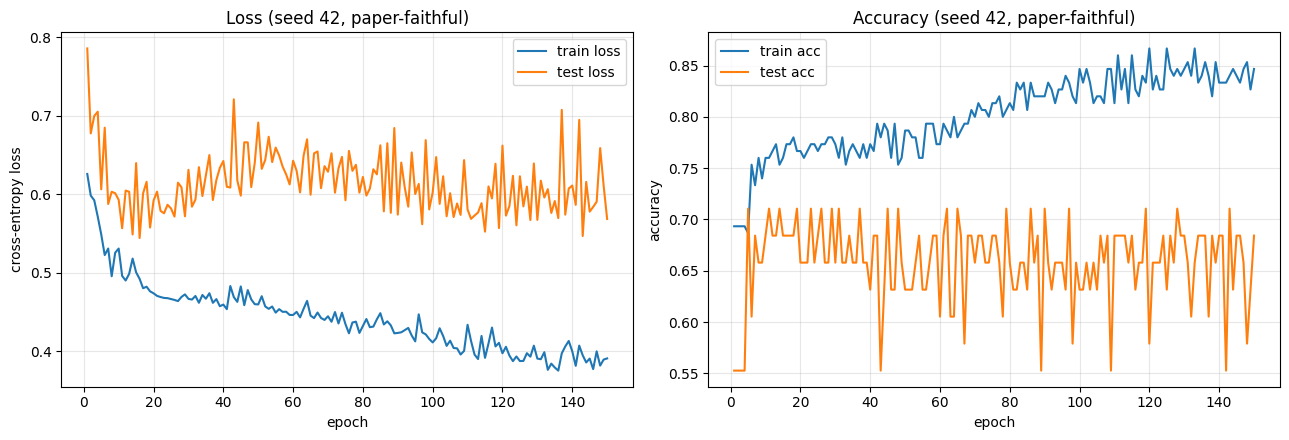

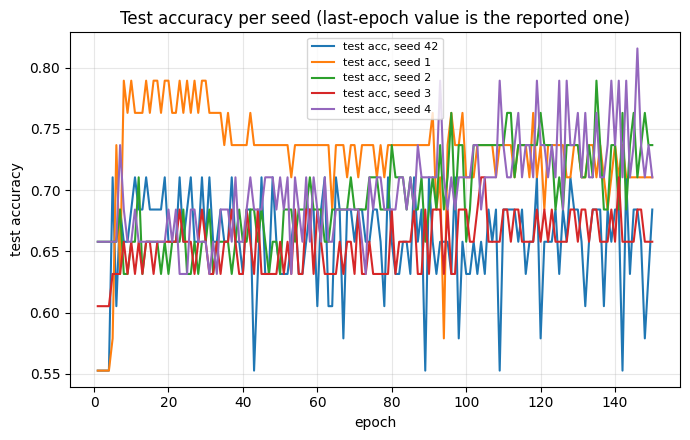

max test accuracy over the run (NOT reported as the result, shown only for transparency): 0.7105


In [18]:
primary = log[(log['seed'] == SEEDS[0]) & (log['config'] == FAITHFUL.name)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(primary['epoch'], primary['train_loss'], label='train loss')
axes[0].plot(primary['epoch'], primary['test_loss'], label='test loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('cross-entropy loss')
axes[0].set_title('Loss (seed %d, %s)' % (SEEDS[0], FAITHFUL.name))
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(primary['epoch'], primary['train_acc'], label='train acc')
axes[1].plot(primary['epoch'], primary['test_acc'], label='test acc')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('accuracy')
axes[1].set_title('Accuracy (seed %d, %s)' % (SEEDS[0], FAITHFUL.name))
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for seed in SEEDS:
    sub = log[(log['seed'] == seed) & (log['config'] == FAITHFUL.name)]
    ax.plot(sub['epoch'], sub['test_acc'], label='test acc, seed %d' % seed)
ax.set_xlabel('epoch')
ax.set_ylabel('test accuracy')
ax.grid(alpha=0.3)
ax.set_title('Test accuracy per seed (last-epoch value is the reported one)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print('max test accuracy over the run (NOT reported as the result, shown only for transparency): %.4f'
      % primary['test_acc'].max())

In [19]:
accs = np.array(final_accuracies, dtype=float) * 100.0
per_seed = pd.DataFrame({'seed': SEEDS, 'final_test_acc_percent': np.round(accs, 2)})

print('=' * 78)
print('PART A - FINAL RESULTS (last-epoch test accuracy, no test-set model selection)')
print('=' * 78)
print('configuration : %d x GCNConv(%d) + ReLU -> simplicial pooling (n=%d, max_clique=%d)'
      % (FAITHFUL.num_gcn_layers, FAITHFUL.hidden, FAITHFUL.pool_n, FAITHFUL.max_clique))
print('                -> %s readout -> Linear(%d)' % (FAITHFUL.readout, dataset.num_classes))
print('optimiser      : Adam(lr=%s, weight_decay=%s), CrossEntropyLoss, %d epochs, batch %d, %d/%d split'
      % (FAITHFUL.lr, FAITHFUL.weight_decay, FAITHFUL.epochs, FAITHFUL.batch_size,
         int(round(100 * FAITHFUL.train_fraction)),
         int(round(100 * (1 - FAITHFUL.train_fraction)))))
print()
print('pooling over the whole test set (averaged over graphs and seeds):')
_ps = pd.DataFrame(pool_stats_per_seed).T
print('  vertices per graph  %.2f -> %.2f  (ratio %.3f)'
      % (_ps['mean_nodes_before'].mean(), _ps['mean_nodes_after'].mean(),
         _ps['mean_compression_ratio'].mean()))
print('  simplices per graph %.2f -> %.2f  (maximal simplices kept)'
      % (_ps['mean_simplices_before'].mean(), _ps['mean_simplices_kept'].mean()))
print()
display(per_seed)
print('primary seed %d, last-epoch test accuracy : %.2f%%' % (SEEDS[0], accs[0]))
if len(accs) > 1:
    print('mean +/- std over %d seeds %s : %.2f +/- %.2f  (min %.2f, max %.2f)'
          % (len(accs), SEEDS, accs.mean(), accs.std(ddof=1), accs.min(), accs.max()))
else:
    print('mean over %d seed: %.2f%%' % (len(accs), accs.mean()))
print()
print('The paper reports ~71%%. The expected band for this faithful setup is 65-75%%.')
print('Nothing here is tuned: same architecture, optimiser, epochs and lr for every seed.')

PART A - FINAL RESULTS (last-epoch test accuracy, no test-set model selection)
configuration : 3 x GCNConv(64) + ReLU -> simplicial pooling (n=1, max_clique=3)
                -> mean readout -> Linear(2)
optimiser      : Adam(lr=0.01, weight_decay=0.0), CrossEntropyLoss, 150 epochs, batch 32, 80/20 split

pooling over the whole test set (averaged over graphs and seeds):
  vertices per graph  17.59 -> 19.34  (ratio 1.099)
  simplices per graph 36.94 -> 19.34  (maximal simplices kept)



,seed,final_test_acc_percent
0,42,68.42
1,1,71.05
2,2,73.68
3,3,65.79
4,4,71.05


primary seed 42, last-epoch test accuracy : 68.42%
mean +/- std over 5 seeds [42, 1, 2, 3, 4] : 70.00 +/- 3.00  (min 65.79, max 73.68)

The paper reports ~71%%. The expected band for this faithful setup is 65-75%%.
Nothing here is tuned: same architecture, optimiser, epochs and lr for every seed.


In [20]:
# -----------------------------------------------------------------------------
# Reproducibility probe: same Part A config and seed, two fresh runs.
# This is deliberately outside the cached Part A table.
# -----------------------------------------------------------------------------
if PROBE_PART_A:
    PART_A_PROBE_DF = run_part_a_probe()
    if bool(PART_A_PROBE_DF['identical_logits'].iloc[0]):
        print('The Part A run is numerically reproducible in this environment.')
    else:
        print('The Part A run is NOT numerically identical across two fresh runs.')
        print('Report this honestly; it is a property of the original training code, not of the cache.')
else:
    print('PROBE_PART_A is False; skipping the Part A reproducibility probe.')


Part A probe: two fresh runs, seed 42, 150 epochs
  probe run 1/2
  probe run 2/2


,seed,epochs,accuracy_run_1,accuracy_run_2,abs_accuracy_difference,max_abs_logit_difference,identical_accuracy,identical_logits
0,42,150,0.684211,0.684211,0.0,0.0,True,True


The Part A run is numerically reproducible in this environment.


## Part B - leakage-controlled benchmark

Part B is independent of Part A's reported result. It uses nested validation-only selection, fixed
method hyper-parameters, outer-test evaluation only after selection, two training seeds, and paired
statistics over outer folds.

The default `PROFILE` is `smoke`. It is intentionally small and is meant to verify that the whole
pipeline runs. Use `reduced` or `standard_core` for reportable results. Optional datasets are OFF.


In [34]:
# =============================================================================
# PART B CONFIGURATION
# =============================================================================
CORE_DATASETS = ('MUTAG', 'PROTEINS', 'IMDB-BINARY', 'NCI1')
CORE_METHODS = ('NoPool', 'SAGPool', 'EdgePool', 'DiffPool', 'FPool', 'Simplicial')
METHOD_KIND = {
    'NoPool': 'none',
    'SAGPool': 'sag',
    'EdgePool': 'edge',
    'DiffPool': 'diff',
    'FPool': 'fp',
    'Simplicial': 'simplicial',
}

DATASET_NOTES = {
    'MUTAG': 'Small molecules; node labels; 2 classes; dense triangles are rare.',
    'PROTEINS': 'Protein graphs; node labels; 2 classes; larger than MUTAG.',
    'IMDB-BINARY': 'Featureless social graphs; degree one-hot fitted on outer train only.',
    'NCI1': 'Chemical graphs; node labels; 2 classes; 5 outer folds.',
    'COLLAB': 'Optional, OFF: 5,000 dense featureless graphs; clique enumeration is expensive.',
    'ENZYMES': 'Optional, OFF: 600 graphs, 6 classes, node attributes.',
    'IMDB-MULTI': 'Optional, OFF: 1,500 featureless graphs, 3 classes.',
}

FEATURELESS_DATASETS = {
    'IMDB-BINARY', 'IMDB-MULTI', 'COLLAB', 'REDDIT-BINARY',
    'REDDIT-MULTI-5K', 'REDDIT-MULTI-12K',
}


@dataclass
class BenchConfig:
    profile: str = 'smoke'
    datasets: Tuple[str, ...] = ('MUTAG',)
    methods: Tuple[str, ...] = CORE_METHODS
    architectures: Tuple[str, ...] = ('R', 'H')
    seeds: Tuple[int, ...] = (0,)
    outer_folds: Dict[str, int] = field(default_factory=lambda: {'MUTAG': 2})
    inner_splits: Dict[str, int] = field(default_factory=lambda: {'MUTAG': 2})
    inner_val_fraction: float = 0.2
    outer_split_seed: int = 20240
    inner_split_seed: int = 20241

    search_trials: int = 1
    hidden_grid: Tuple[int, ...] = (32, 64)
    lr_grid: Tuple[float, ...] = (0.01, 0.005)
    dropout: float = 0.5
    weight_decay: float = 5e-4
    grad_clip: float = 1.0
    max_epochs: int = 3
    patience: int = 2
    min_epochs: int = 1
    batch_size: int = 32
    readout: str = 'mean+max+sum'
    use_batchnorm: bool = True
    use_residual: bool = True

    pool_n: int = 1
    max_clique: int = 3
    feature_agg: str = 'mean'
    deduplicate: bool = False
    transpose_between_iterations: bool = False
    diffpool_aux_weight: float = 1.0
    sag_ratio: float = 0.5
    edge_dropout: float = 0.0
    edge_add_to_score: float = 0.5

    final_refit_on_full_outer_train: bool = True
    checkpoint_every: int = 10
    bootstrap_samples: int = 10000
    bootstrap_seed: int = 12345
    structure_shard_size: int = 500

    def as_dict(self) -> Dict[str, Any]:
        return asdict(self)

    def fingerprint(self) -> str:
        return stable_hash(self.as_dict())


PROFILE_SPECS = {
    'smoke': dict(
        datasets=('MUTAG',),
        outer_folds={'MUTAG': 2},
        inner_splits={'MUTAG': 2},
        seeds=(0,),
        search_trials=1,
        max_epochs=3,
        patience=2,
        min_epochs=1,
        batch_size=16,
        architectures=('R', 'H'),
    ),
    'reduced': dict(
        datasets=CORE_DATASETS,
        outer_folds={'MUTAG': 5, 'PROTEINS': 5, 'IMDB-BINARY': 5, 'NCI1': 3},
        inner_splits={'MUTAG': 2},
        seeds=(0,),
        search_trials=2,
        max_epochs=50,
        patience=8,
        min_epochs=5,
        batch_size=32,
        architectures=('R', 'H'),
    ),
    'standard_core': dict(
        datasets=CORE_DATASETS,
        outer_folds={'MUTAG': 10, 'PROTEINS': 10, 'IMDB-BINARY': 10, 'NCI1': 5},
        inner_splits={'MUTAG': 3},
        seeds=(0, 1),
        search_trials=4,
        max_epochs=150,
        patience=15,
        min_epochs=10,
        batch_size=32,
        architectures=('R', 'H'),
    ),
    'full': dict(
        datasets=CORE_DATASETS,
        outer_folds={'MUTAG': 10, 'PROTEINS': 10, 'IMDB-BINARY': 10, 'NCI1': 5},
        inner_splits={'MUTAG': 3},
        seeds=(0, 1),
        search_trials=4,
        max_epochs=150,
        patience=15,
        min_epochs=10,
        batch_size=32,
        architectures=('R', 'H'),
    ),
}


def make_bench_config(profile: str = 'smoke') -> BenchConfig:
    if profile not in PROFILE_SPECS:
        raise ValueError('unknown profile %r; choose from %s' % (profile, sorted(PROFILE_SPECS)))
    spec = dict(PROFILE_SPECS[profile])
    spec['profile'] = profile
    return BenchConfig(**spec)


PROFILE = 'smoke'
BENCH_CFG = make_bench_config(PROFILE)
RUN_BENCHMARK = True
MAX_JOBS = None
RESUME = True
RETRY_FAILED = True

print('PROFILE       ', BENCH_CFG.profile)
print('datasets      ', BENCH_CFG.datasets)
print('methods       ', BENCH_CFG.methods)
print('architectures ', BENCH_CFG.architectures)
print('seeds         ', BENCH_CFG.seeds)
print('outer folds   ', BENCH_CFG.outer_folds)
print('inner splits  ', BENCH_CFG.inner_splits)
print('search trials ', BENCH_CFG.search_trials)
print('max epochs    ', BENCH_CFG.max_epochs)
print('config hash   ', BENCH_CFG.fingerprint())


PROFILE        smoke
datasets       ('MUTAG',)
methods        ('NoPool', 'SAGPool', 'EdgePool', 'DiffPool', 'FPool', 'Simplicial')
architectures  ('R', 'H')
seeds          (0,)
outer folds    {'MUTAG': 2}
inner splits   {'MUTAG': 2}
search trials  1
max epochs     3
config hash    c585852cc2ca0616ac72


In [35]:
# =============================================================================
# ROBUST CLIQUE-COMPLEX CONSTRUCTION AND PRECOMPUTED SIMPLICIAL STRUCTURE
# =============================================================================
import networkx as nx

def _edge_list_from_index(edge_index, num_nodes: int) -> List[Tuple[int, int]]:
    if edge_index is None or edge_index.numel() == 0:
        return []
    ei = edge_index.detach().cpu().numpy()
    edges = set()
    for a, b in zip(ei[0].tolist(), ei[1].tolist()):
        a, b = int(a), int(b)
        if a == b or a < 0 or b < 0 or a >= num_nodes or b >= num_nodes:
            continue
        edges.add((a, b) if a < b else (b, a))
    return sorted(edges)


def enumerate_simplices_robust(edge_index, num_nodes: int, max_clique: int = 3,
                               time_limit: float = 3.0,
                               max_simplices: int = 200000):
    """
    Enumerate all cliques up to max_clique in the same order as the original
    notebook (vertices, then edges, then triangles, ...), but without the
    O(n**k) brute-force guard that silently dropped triangles for n > 58.
    Falls back to the 1-skeleton if a graph is too large or too dense.
    """
    if max_clique < 1:
        raise ValueError('max_clique must be >= 1')
    edges = _edge_list_from_index(edge_index, num_nodes)
    G = nx.Graph()
    G.add_nodes_from(range(num_nodes))
    G.add_edges_from(edges)

    groups: Dict[int, List[Tuple[int, ...]]] = defaultdict(list)
    start = time.time()
    fallback = False
    reason = ''
    count = 0
    try:
        for clique in nx.enumerate_all_cliques(G):
            size = len(clique)
            if size > max_clique:
                break
            groups[size].append(tuple(sorted(clique)))
            count += 1
            if count > max_simplices:
                raise RuntimeError('max_simplices=%d exceeded' % max_simplices)
            if time.time() - start > time_limit:
                raise TimeoutError('clique enumeration exceeded %.1fs' % time_limit)
        simplices: List[List[int]] = []
        for size in sorted(groups):
            for clique in sorted(groups[size]):
                simplices.append(list(clique))
    except Exception as exc:
        fallback = True
        reason = '%s: %s' % (type(exc).__name__, exc)
        simplices = [[i] for i in range(num_nodes)] + [list(e) for e in edges]

    if not simplices and num_nodes > 0:
        simplices = [[i] for i in range(num_nodes)]
    return simplices, fallback, reason


def maximal_simplices(simplices: Sequence[Sequence[int]]) -> List[List[int]]:
    """Maximal elements under proper set inclusion, preserving the input order."""
    sets = [frozenset(s) for s in simplices]
    maximal_sets: List[frozenset] = []
    for idx in sorted(range(len(sets)), key=lambda i: -len(sets[i])):
        s = sets[idx]
        if not any(s < t for t in maximal_sets):
            maximal_sets.append(s)
    keep = set(maximal_sets)
    return [list(s) for s in simplices if frozenset(s) in keep]


def pooled_edges_from_members(members: Sequence[Sequence[int]]) -> np.ndarray:
    """Two pooled nodes are adjacent iff their member sets intersect."""
    incidence = defaultdict(list)
    for pooled_idx, member in enumerate(members):
        for v in member:
            incidence[int(v)].append(pooled_idx)
    edges = set()
    for pooled_list in incidence.values():
        if len(pooled_list) < 2:
            continue
        for a, b in combinations(sorted(pooled_list), 2):
            edges.add((a, b))
    if not edges:
        return np.zeros((2, 0), dtype=np.int64)
    directed = []
    for a, b in sorted(edges):
        directed.append((a, b))
        directed.append((b, a))
    arr = np.asarray(directed, dtype=np.int64).T
    return arr


def compute_graph_structure(edge_index, num_nodes: int, cfg: BenchConfig) -> Dict[str, Any]:
    """Compute one graph's simplicial pooling structure (no features involved)."""
    start = time.time()
    simplices, fallback, reason = enumerate_simplices_robust(
        edge_index, num_nodes, cfg.max_clique,
        time_limit=3.0, max_simplices=200000,
    )

    if cfg.pool_n == 1 and not cfg.deduplicate and not cfg.transpose_between_iterations:
        members = maximal_simplices(simplices)
    else:
        M = np.zeros((num_nodes, len(simplices)), dtype=np.int8)
        for j, simplex in enumerate(simplices):
            for v in simplex:
                M[int(v), j] = 1
        M_red, vertex_idx, simplex_idx = simplicial_pooling(
            M, n=cfg.pool_n, deduplicate=cfg.deduplicate,
            transpose_between_iterations=cfg.transpose_between_iterations,
        )
        members = [list(simplices[int(j)]) for j in simplex_idx]

    if not members and num_nodes > 0:
        members = [[i] for i in range(num_nodes)]

    pooled_edges = pooled_edges_from_members(members)
    return {
        'members': [[int(v) for v in m] for m in members],
        'pooled_edges': pooled_edges,
        'num_nodes': int(num_nodes),
        'num_pooled': int(len(members)),
        'num_simplices': int(len(simplices)),
        'fallback': bool(fallback),
        'fallback_reason': reason,
        'seconds': float(time.time() - start),
    }


def structure_cache_dir(cfg: BenchConfig) -> Path:
    tag = 'structures_mc%d_n%d_dedup%d_trans%d_%s' % (
        cfg.max_clique, cfg.pool_n, int(cfg.deduplicate),
        int(cfg.transpose_between_iterations), BENCHMARK_VERSION,
    )
    return CACHE_DIR / tag


def build_or_load_structures(bundle, cfg: BenchConfig, force: bool = False,
                             verbose: bool = True) -> List[Dict[str, Any]]:
    """Sharded, resumable structure cache keyed by topology and pooling config."""
    cache_dir = structure_cache_dir(cfg)
    cache_dir.mkdir(parents=True, exist_ok=True)
    n_graphs = len(bundle.data)
    shard_size = int(cfg.structure_shard_size)
    structures: List[Optional[Dict[str, Any]]] = [None] * n_graphs
    n_fallback = 0
    n_loaded = 0
    n_computed = 0

    for start in range(0, n_graphs, shard_size):
        end = min(n_graphs, start + shard_size)
        path = cache_dir / ('%s_shard_%05d_%05d.pt' % (safe_name(bundle.name), start, end))
        expected_meta = {
            'dataset': bundle.name,
            'start': start,
            'end': end,
            'max_clique': cfg.max_clique,
            'pool_n': cfg.pool_n,
            'deduplicate': cfg.deduplicate,
            'transpose': cfg.transpose_between_iterations,
            'version': BENCHMARK_VERSION,
        }
        payload = None
        if path.exists() and not force:
            try:
                payload = torch.load(path, map_location='cpu', weights_only=False)
                if payload.get('meta') != expected_meta:
                    payload = None
            except Exception:
                payload = None

        if payload is not None:
            shard = payload['structures']
            for offset, struct in enumerate(shard):
                structures[start + offset] = struct
                n_loaded += 1
                n_fallback += int(bool(struct.get('fallback', False)))
            continue

        shard = []
        for idx in range(start, end):
            d = bundle.data[idx]
            struct = compute_graph_structure(d.edge_index, int(d.num_nodes), cfg)
            shard.append(struct)
            structures[idx] = struct
            n_computed += 1
            n_fallback += int(bool(struct.get('fallback', False)))
        atomic_torch_save({'meta': expected_meta, 'structures': shard}, path)

    if any(s is None for s in structures):
        raise RuntimeError('structure cache incomplete')
    if verbose:
        print('  structures: %d graphs (%d loaded, %d computed, %d fallback)'
              % (n_graphs, n_loaded, n_computed, n_fallback))
    return structures


In [36]:
# =============================================================================
# DATASETS, FEATURE TYPES AND THE DATASET AUDIT
# =============================================================================
@dataclass
class DatasetBundle:
    name: str
    data: List[Data]
    y: np.ndarray
    num_classes: int
    raw_num_features: int
    feature_kind: str
    max_nodes: int
    note: str = ''


_BUNDLE_CACHE: Dict[str, DatasetBundle] = {}


def _load_tu_dataset(name: str) -> TUDataset:
    last_exc = None
    for use_node_attr in (True, False):
        try:
            return TUDataset(root=str(DATA_DIR), name=name, use_node_attr=use_node_attr)
        except Exception as exc:
            last_exc = exc
    raise last_exc


def _infer_feature_kind(name: str, data_list: Sequence[Data]) -> str:
    if name in FEATURELESS_DATASETS:
        return 'degree'
    x = data_list[0].x
    if x is None or x.numel() == 0:
        return 'degree'
    sample = torch.cat([d.x.view(-1, d.x.size(-1)) for d in data_list[:min(200, len(data_list))]], dim=0)
    vals = torch.unique(sample)
    if vals.numel() <= 2 and bool(torch.all((vals == 0) | (vals == 1))):
        return 'binary'
    return 'continuous'


def load_bundle(name: str, force: bool = False) -> DatasetBundle:
    if not force and name in _BUNDLE_CACHE:
        return _BUNDLE_CACHE[name]
    raw = _load_tu_dataset(name)
    data_list: List[Data] = []
    ys = []
    for idx in range(len(raw)):
        d = raw[idx].clone()
        if d.x is None or d.x.numel() == 0:
            d.x = torch.ones((int(d.num_nodes), 1), dtype=torch.float)
        d.x = d.x.float()
        d.edge_attr = None
        y = d.y.view(-1)
        if y.numel() == 0:
            raise ValueError('graph %d in %s has no label' % (idx, name))
        d.y = y[0].view(1).long()
        d.graph_id = torch.tensor([idx], dtype=torch.long)
        data_list.append(d)
        ys.append(int(d.y.item()))

    y_arr = np.asarray(ys, dtype=np.int64)
    num_classes = int(len(np.unique(y_arr)))
    kind = _infer_feature_kind(name, data_list)
    max_nodes = max((int(d.num_nodes) for d in data_list), default=0)
    bundle = DatasetBundle(
        name=name,
        data=data_list,
        y=y_arr,
        num_classes=num_classes,
        raw_num_features=int(data_list[0].x.size(-1)) if data_list else 0,
        feature_kind=kind,
        max_nodes=max_nodes,
        note=DATASET_NOTES.get(name, ''),
    )
    _BUNDLE_CACHE[name] = bundle
    return bundle


def audit_datasets(names: Sequence[str] = CORE_DATASETS, verbose: bool = True) -> pd.DataFrame:
    rows = []
    for name in names:
        try:
            bundle = load_bundle(name)
            nodes = [int(d.num_nodes) for d in bundle.data]
            edges = [int(d.num_edges) for d in bundle.data]
            rows.append({
                'dataset': name,
                'graphs': len(bundle.data),
                'classes': bundle.num_classes,
                'node_features': bundle.raw_num_features,
                'feature_kind': bundle.feature_kind,
                'nodes_min': int(np.min(nodes)) if nodes else 0,
                'nodes_mean': round(float(np.mean(nodes)), 2) if nodes else 0.0,
                'nodes_max': int(np.max(nodes)) if nodes else 0,
                'edges_mean': round(float(np.mean(edges)), 2) if edges else 0.0,
                'note': bundle.note,
            })
        except Exception as exc:
            rows.append({
                'dataset': name, 'graphs': None, 'classes': None,
                'node_features': None, 'feature_kind': 'ERROR',
                'nodes_min': None, 'nodes_mean': None, 'nodes_max': None,
                'edges_mean': None, 'note': '%s: %s' % (type(exc).__name__, exc),
            })
    df = pd.DataFrame(rows)
    if verbose:
        display(df)
    return df


AUDIT_DF = audit_datasets(CORE_DATASETS, verbose=True)

OPTIONAL_AUDIT_DF = pd.DataFrame([
    {'dataset': name, 'loaded': False, 'reason': DATASET_NOTES[name]}
    for name in ('COLLAB', 'ENZYMES', 'IMDB-MULTI')
])
print('Optional candidates (OFF by default):')
display(OPTIONAL_AUDIT_DF)


,dataset,graphs,classes,node_features,feature_kind,nodes_min,nodes_mean,nodes_max,edges_mean,note
0,MUTAG,188,2,7,binary,10,17.93,28,39.59,Small molecules; node labels; 2 classes; dense...
1,PROTEINS,1113,2,4,continuous,4,39.06,620,145.63,Protein graphs; node labels; 2 classes; larger...
2,IMDB-BINARY,1000,2,1,degree,12,19.77,136,193.06,Featureless social graphs; degree one-hot fitt...
3,NCI1,4110,2,37,binary,3,29.87,111,64.60,Chemical graphs; node labels; 2 classes; 5 out...


Optional candidates (OFF by default):


,dataset,loaded,reason
0,COLLAB,False,"Optional, OFF: 5,000 dense featureless graphs;..."
1,ENZYMES,False,"Optional, OFF: 600 graphs, 6 classes, node att..."
2,IMDB-MULTI,False,"Optional, OFF: 1,500 featureless graphs, 3 cla..."


In [37]:
# =============================================================================
# FEATURE PREPROCESSING AND LEAKAGE-CONTROLLED SPLITS
# =============================================================================
from sklearn.model_selection import StratifiedKFold, train_test_split


@dataclass
class FeatureTransform:
    kind: str
    num_features: int
    max_degree: Optional[int] = None
    mean: Optional[torch.Tensor] = None
    std: Optional[torch.Tensor] = None


def _node_degrees(d: Data) -> torch.Tensor:
    if d.num_edges == 0:
        return torch.zeros(int(d.num_nodes), dtype=torch.long)
    return degree(d.edge_index[0], num_nodes=int(d.num_nodes)).long()


def fit_feature_transform(bundle: DatasetBundle, train_idx: Sequence[int]) -> FeatureTransform:
    """Fit every data-dependent feature statistic on OUTER-TRAIN graphs only."""
    if bundle.feature_kind == 'degree':
        max_deg = 0
        for idx in train_idx:
            deg = _node_degrees(bundle.data[int(idx)])
            if deg.numel():
                max_deg = max(max_deg, int(deg.max().item()))
        return FeatureTransform(kind='degree', num_features=max_deg + 1, max_degree=max_deg)

    if bundle.feature_kind == 'binary':
        return FeatureTransform(kind='binary', num_features=bundle.raw_num_features)

    if bundle.feature_kind == 'continuous':
        xs = []
        for idx in train_idx:
            xs.append(bundle.data[int(idx)].x.view(-1, bundle.raw_num_features))
        if not xs:
            raise ValueError('no training nodes for continuous feature fit')
        x = torch.cat(xs, dim=0).double()
        mean = x.mean(dim=0).float()
        std = x.std(dim=0, unbiased=False).float()
        std = torch.where(std < 1e-8, torch.ones_like(std), std)
        return FeatureTransform(kind='continuous', num_features=bundle.raw_num_features,
                                mean=mean, std=std)

    raise ValueError('unknown feature kind %r' % bundle.feature_kind)


def apply_feature_transform(bundle: DatasetBundle, transform: FeatureTransform,
                            indices: Sequence[int]) -> List[Data]:
    out: List[Data] = []
    for idx in indices:
        d = bundle.data[int(idx)].clone()
        if transform.kind == 'degree':
            deg = _node_degrees(d).clamp(max=int(transform.max_degree))
            onehot = F.one_hot(deg, num_classes=int(transform.num_features)).float()
            d.x = onehot
        elif transform.kind == 'binary':
            d.x = d.x.float()
        elif transform.kind == 'continuous':
            d.x = (d.x.float() - transform.mean) / transform.std
        else:
            raise ValueError(transform.kind)
        d.graph_id = torch.tensor([int(idx)], dtype=torch.long)
        out.append(d)
    return out


def prepare_all_features(bundle: DatasetBundle, transform: FeatureTransform) -> List[Data]:
    return apply_feature_transform(bundle, transform, list(range(len(bundle.data))))


def make_outer_splits(bundle: DatasetBundle, cfg: BenchConfig) -> List[Dict[str, Any]]:
    n_splits = int(cfg.outer_folds.get(bundle.name, 5))
    if n_splits < 2:
        raise ValueError('outer folds must be >= 2')
    class_counts = np.bincount(bundle.y, minlength=bundle.num_classes)
    if np.any(class_counts[class_counts > 0] < n_splits):
        raise ValueError('%s has too few members in a class for %d outer folds'
                         % (bundle.name, n_splits))
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=cfg.outer_split_seed)
    splits = []
    for fold, (train_idx, test_idx) in enumerate(skf.split(np.zeros(len(bundle.y)), bundle.y)):
        splits.append({
            'fold': int(fold),
            'train_idx': np.asarray(train_idx, dtype=np.int64),
            'test_idx': np.asarray(test_idx, dtype=np.int64),
        })
    assert_outer_splits(bundle, splits)
    return splits


def assert_outer_splits(bundle: DatasetBundle, splits: Sequence[Dict[str, Any]]) -> None:
    all_test = np.concatenate([s['test_idx'] for s in splits])
    if len(all_test) != len(bundle.y) or len(np.unique(all_test)) != len(bundle.y):
        raise AssertionError('outer test folds do not partition the dataset')
    if not np.array_equal(np.sort(all_test), np.arange(len(bundle.y))):
        raise AssertionError('outer test folds do not cover all graphs exactly once')
    for s in splits:
        tr = set(int(i) for i in s['train_idx'])
        te = set(int(i) for i in s['test_idx'])
        if tr & te:
            raise AssertionError('outer train/test overlap')
        if len(tr) + len(te) != len(bundle.y):
            raise AssertionError('outer train/test do not cover the dataset')


def make_inner_splits(bundle: DatasetBundle, outer_train_idx: Sequence[int],
                      cfg: BenchConfig, outer_fold: int) -> List[Dict[str, Any]]:
    """MUTAG: stratified 3-fold; all other datasets: one stratified 80/20 split."""
    train_idx = np.asarray(outer_train_idx, dtype=np.int64)
    n_inner = int(cfg.inner_splits.get(bundle.name, 1))
    seed = int(cfg.inner_split_seed + 1000 * outer_fold)
    if n_inner >= 2:
        skf = StratifiedKFold(n_splits=n_inner, shuffle=True, random_state=seed)
        out = []
        for j, (itr, iva) in enumerate(skf.split(np.zeros(len(train_idx)), bundle.y[train_idx])):
            out.append({'inner_fold': int(j),
                        'train_idx': train_idx[itr],
                        'val_idx': train_idx[iva]})
    else:
        try:
            itr, iva = train_test_split(
                train_idx, test_size=float(cfg.inner_val_fraction),
                stratify=bundle.y[train_idx], random_state=seed,
            )
        except ValueError:
            itr, iva = train_test_split(
                train_idx, test_size=float(cfg.inner_val_fraction), random_state=seed,
            )
        out = [{'inner_fold': 0,
                'train_idx': np.asarray(itr, dtype=np.int64),
                'val_idx': np.asarray(iva, dtype=np.int64)}]
    assert_inner_splits(bundle, train_idx, out)
    return out


def assert_inner_splits(bundle: DatasetBundle, outer_train_idx: Sequence[int],
                        inner_splits: Sequence[Dict[str, Any]]) -> None:
    outer_train = set(int(i) for i in outer_train_idx)
    for s in inner_splits:
        tr = set(int(i) for i in s['train_idx'])
        va = set(int(i) for i in s['val_idx'])
        if tr & va:
            raise AssertionError('inner train/val overlap')
        if not (tr | va) <= outer_train:
            raise AssertionError('inner split contains an outer-test graph')
        if len(tr) == 0 or len(va) == 0:
            raise AssertionError('empty inner split')


In [38]:
# =============================================================================
# POOLING LAYERS
# =============================================================================
class NoPoolLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.last_aux_loss = 0.0

    def forward(self, x, edge_index, batch, graph_id=None):
        self.last_aux_loss = 0.0
        return x, edge_index, batch, None


class SimplicialBatchPool(nn.Module):
    """Uses precomputed maximal-simplex structures; no combinatorial work in forward."""

    def __init__(self, structures: Sequence[Dict[str, Any]], feature_agg: str = 'mean'):
        super().__init__()
        self.structures = structures
        self.feature_agg = feature_agg
        self.last_aux_loss = 0.0

    def forward(self, x, edge_index, batch, graph_id=None):
        if graph_id is None:
            raise ValueError('SimplicialBatchPool needs data.graph_id')
        device = x.device
        num_graphs = int(batch.max().item()) + 1
        order = torch.argsort(batch, stable=True)
        counts = torch.bincount(batch, minlength=num_graphs)
        ptr = torch.cat([torch.zeros(1, dtype=torch.long, device=device), counts.cumsum(0)])

        rows: List[int] = []
        cols: List[int] = []
        vals: List[float] = []
        batch_out: List[int] = []
        pooled_edges: List[torch.Tensor] = []
        pooled_offset = 0

        for b in range(num_graphs):
            gid = int(graph_id[b].item())
            struct = self.structures[gid]
            members = struct['members']
            node_idx = order[int(ptr[b]):int(ptr[b + 1])]
            if not members:
                members = [[]]
            for s, member in enumerate(members):
                if len(member) == 0:
                    continue
                w = 1.0 / len(member) if self.feature_agg == 'mean' else 1.0
                rows.extend([pooled_offset + s] * len(member))
                cols.extend([int(node_idx[int(v)].item()) for v in member])
                vals.extend([w] * len(member))
            pe = torch.as_tensor(struct['pooled_edges'], dtype=torch.long, device=device)
            if pe.numel():
                pooled_edges.append(pe + pooled_offset)
            batch_out.extend([b] * len(members))
            pooled_offset += len(members)

        if pooled_offset == 0:
            return x, edge_index, batch, None
        idx = torch.tensor([rows, cols], dtype=torch.long, device=device)
        val = torch.tensor(vals, dtype=x.dtype, device=device)
        P = torch.sparse_coo_tensor(idx, val, (pooled_offset, x.size(0))).coalesce()
        x_out = torch.sparse.mm(P, x)
        if pooled_edges:
            ei_out = torch.cat(pooled_edges, dim=1)
        else:
            ei_out = torch.zeros((2, 0), dtype=torch.long, device=device)
        b_out = torch.tensor(batch_out, dtype=torch.long, device=device)
        self.last_aux_loss = 0.0
        return x_out, ei_out, b_out, None


class SAGPoolLayer(nn.Module):
    def __init__(self, in_channels: int, ratio: float = 0.5):
        super().__init__()
        self.pool = SAGPooling(in_channels, ratio=ratio)
        self.last_aux_loss = 0.0

    def forward(self, x, edge_index, batch, graph_id=None):
        x, edge_index, _, batch, _, _ = self.pool(x, edge_index, batch=batch)
        self.last_aux_loss = 0.0
        return x, edge_index, batch, None


class EdgePoolLayer(nn.Module):
    def __init__(self, in_channels: int, dropout: float = 0.0,
                 add_to_edge_score: float = 0.5):
        super().__init__()
        self.pool = EdgePooling(in_channels, dropout=dropout,
                                add_to_edge_score=add_to_edge_score)
        self.last_aux_loss = 0.0

    def forward(self, x, edge_index, batch, graph_id=None):
        x, edge_index, batch, _ = self.pool(x, edge_index, batch)
        self.last_aux_loss = 0.0
        return x, edge_index, batch, None


def _dense_inputs(x, edge_index, batch, logits):
    num_graphs = int(batch.max().item()) + 1
    max_n = int(torch.bincount(batch, minlength=num_graphs).max().item())
    h_dense, mask = to_dense_batch(x, batch, max_num_nodes=max_n, batch_size=num_graphs)
    s_dense, _ = to_dense_batch(logits, batch, max_num_nodes=max_n, batch_size=num_graphs)
    adj = to_dense_adj(edge_index, batch, max_num_nodes=max_n, batch_size=num_graphs)
    return h_dense, adj, s_dense, mask


def _variable_soft_pool(h_dense, adj, s_logits, mask, c_max: int, aux_weight: float = 0.0):
    """
    Per-graph soft clustering with k_g = clamp(ceil(0.5*n_g), 2, C_max).
    Empty clusters are removed. Soft pooled adjacency weights are kept.
    """
    device = h_dense.device
    batch_size = h_dense.size(0)
    xs: List[torch.Tensor] = []
    eis: List[torch.Tensor] = []
    ews: List[torch.Tensor] = []
    bs: List[torch.Tensor] = []
    link_terms: List[torch.Tensor] = []
    ent_terms: List[torch.Tensor] = []
    offset = 0

    for b in range(batch_size):
        n_b = int(mask[b].sum().item())
        if n_b == 0:
            continue
        k_b = min(max(int(math.ceil(0.5 * n_b)), 2), int(c_max))
        logits = s_logits[b, :n_b, :k_b]
        S = torch.softmax(logits, dim=-1)
        xb = h_dense[b, :n_b]
        Ab = adj[b, :n_b, :n_b]
        mass = S.sum(dim=0)
        keep = mass > 1e-8
        if not bool(keep.any()):
            keep = torch.zeros_like(keep)
            keep[0] = True
        Sk = S[:, keep]
        xp = Sk.t() @ xb
        Ap = Sk.t() @ Ab @ Sk
        Ap = Ap - torch.diag_embed(torch.diagonal(Ap))
        xs.append(xp)
        bs.append(torch.full((xp.size(0),), b, dtype=torch.long, device=device))
        i_idx, j_idx = torch.nonzero(Ap.abs() > 1e-8, as_tuple=True)
        eis.append(torch.stack([i_idx + offset, j_idx + offset], dim=0))
        ews.append(Ap[i_idx, j_idx])
        offset += xp.size(0)

        if aux_weight > 0.0:
            link = ((Ab - Sk @ Sk.t()) ** 2).sum() / max(n_b * n_b, 1)
            ent = -(Sk * torch.log(Sk + 1e-9)).sum(dim=1).mean()
            link_terms.append(link)
            ent_terms.append(ent)

    if not xs:
        return None, None, None, None, torch.zeros((), device=device)
    x_out = torch.cat(xs, dim=0)
    edge_index = torch.cat(eis, dim=1) if eis else torch.zeros((2, 0), dtype=torch.long, device=device)
    edge_weight = torch.cat(ews, dim=0) if ews else torch.zeros((0,), dtype=x_out.dtype, device=device)
    batch_out = torch.cat(bs, dim=0)
    aux = torch.zeros((), device=device)
    if aux_weight > 0.0 and link_terms:
        aux = aux_weight * (torch.stack(link_terms).mean() + torch.stack(ent_terms).mean())
    return x_out, edge_index, batch_out, edge_weight, aux


class DiffPoolLayer(nn.Module):
    def __init__(self, in_channels: int, c_max: int, aux_weight: float = 1.0):
        super().__init__()
        self.c_max = int(c_max)
        self.aux_weight = float(aux_weight)
        self.pool_gnn = GCNConv(in_channels, self.c_max)
        self.last_aux_loss = 0.0

    def forward(self, x, edge_index, batch, graph_id=None):
        logits = self.pool_gnn(x, edge_index)
        h, adj, s, mask = _dense_inputs(x, edge_index, batch, logits)
        xp, ei, bo, ew, aux = _variable_soft_pool(
            h, adj, s, mask, self.c_max, aux_weight=self.aux_weight)
        if xp is None:
            self.last_aux_loss = torch.zeros((), device=x.device)
            return x, edge_index, batch, None
        self.last_aux_loss = aux
        return xp, ei, bo, ew


class FPoolLayer(nn.Module):
    """Feature-based soft clustering with one assignment head and no auxiliary loss."""
    def __init__(self, in_channels: int, c_max: int):
        super().__init__()
        self.c_max = int(c_max)
        self.assign = nn.Linear(in_channels, self.c_max)
        self.last_aux_loss = 0.0

    def forward(self, x, edge_index, batch, graph_id=None):
        logits = self.assign(x)
        h, adj, s, mask = _dense_inputs(x, edge_index, batch, logits)
        xp, ei, bo, ew, _ = _variable_soft_pool(h, adj, s, mask, self.c_max, aux_weight=0.0)
        if xp is None:
            self.last_aux_loss = torch.zeros((), device=x.device)
            return x, edge_index, batch, None
        self.last_aux_loss = torch.zeros((), device=x.device)
        return xp, ei, bo, ew


def make_pool_layer(method: str, hidden: int, c_max: int, structures, cfg: BenchConfig):
    kind = METHOD_KIND[method]
    if kind == 'none':
        return NoPoolLayer()
    if kind == 'sag':
        return SAGPoolLayer(hidden, ratio=cfg.sag_ratio)
    if kind == 'edge':
        return EdgePoolLayer(hidden, dropout=cfg.edge_dropout,
                             add_to_edge_score=cfg.edge_add_to_score)
    if kind == 'diff':
        return DiffPoolLayer(hidden, c_max=c_max, aux_weight=cfg.diffpool_aux_weight)
    if kind == 'fp':
        return FPoolLayer(hidden, c_max=c_max)
    if kind == 'simplicial':
        return SimplicialBatchPool(structures, feature_agg=cfg.feature_agg)
    raise ValueError('unknown method %r' % method)


In [39]:
# =============================================================================
# REQUIRED CHECK: PRECOMPUTED STRUCTURE == ORIGINAL PART A POOLING ON MUTAG
# =============================================================================
def _edge_set(edge_index) -> set:
    if edge_index is None or edge_index.numel() == 0:
        return set()
    return set(map(tuple, edge_index.detach().cpu().t().tolist()))


def check_simplicial_structure_equivalence() -> None:
    orig_pool = SimplicialPool(
        n=BENCH_CFG.pool_n, max_clique=BENCH_CFG.max_clique,
        feature_agg=BENCH_CFG.feature_agg, deduplicate=BENCH_CFG.deduplicate,
        transpose_between_iterations=BENCH_CFG.transpose_between_iterations,
    )
    structures = []
    for i in range(len(dataset)):
        d = dataset[i]
        orig_members, _ = orig_pool.pool_single_graph(
            d.edge_index.detach().cpu().numpy(), int(d.num_nodes))
        struct = compute_graph_structure(d.edge_index, int(d.num_nodes), BENCH_CFG)
        structures.append(struct)

        orig_set = sorted(tuple(sorted(int(v) for v in m)) for m in orig_members)
        new_set = sorted(tuple(sorted(int(v) for v in m)) for m in struct['members'])
        if orig_set != new_set:
            raise AssertionError('member mismatch on MUTAG graph %d' % i)

        orig_edges = set()
        for a in range(len(orig_members)):
            for b in range(a + 1, len(orig_members)):
                if set(orig_members[a]) & set(orig_members[b]):
                    orig_edges.add((a, b))
                    orig_edges.add((b, a))
        new_edges = set(map(tuple, struct['pooled_edges'].T.tolist()))
        if orig_edges != new_edges:
            raise AssertionError('pooled-edge mismatch on MUTAG graph %d' % i)

    batch_data = []
    for i in range(min(24, len(dataset))):
        d = dataset[i].clone()
        d.graph_id = torch.tensor([i], dtype=torch.long)
        batch_data.append(d)
    batch = next(iter(DataLoader(batch_data, batch_size=8, shuffle=False)))
    x = torch.randn(batch.num_nodes, 5, generator=torch.Generator().manual_seed(0))
    orig_x, orig_ei, orig_b = orig_pool(x, batch.edge_index, batch.batch)
    new_pool = SimplicialBatchPool(structures, feature_agg=BENCH_CFG.feature_agg)
    new_x, new_ei, new_b, _ = new_pool(x, batch.edge_index, batch.batch, batch.graph_id)
    if new_x.shape != orig_x.shape:
        raise AssertionError('pooled feature shape mismatch')
    if not torch.allclose(new_x, orig_x, atol=1e-6, rtol=1e-6):
        raise AssertionError('pooled features differ from the original layer')
    if _edge_set(new_ei) != _edge_set(orig_ei):
        raise AssertionError('pooled edge sets differ from the original layer')
    if not torch.equal(new_b, orig_b):
        raise AssertionError('pooled batch vector differs from the original layer')

    n_fallback = sum(int(bool(s['fallback'])) for s in structures)
    print('OK: precomputed structures match the original SimplicialPool on all %d MUTAG graphs.'
          % len(dataset))
    print('OK: random-batch pooled features, pooled edge sets and batch vectors are identical.')
    print('MUTAG fallback graphs:', n_fallback)


check_simplicial_structure_equivalence()


OK: precomputed structures match the original SimplicialPool on all 188 MUTAG graphs.
OK: random-batch pooled features, pooled edge sets and batch vectors are identical.
MUTAG fallback graphs: 0


In [40]:
# =============================================================================
# ARCH-R / ARCH-H MODELS
# =============================================================================
class BenchmarkModel(nn.Module):
    """
    Arch-R: 3 pre-pool GCNConv blocks -> pool -> readout -> Linear.
    Arch-H: 2 pre-pool GCNConv blocks -> pool -> 1 post-pool GCNConv -> readout -> Linear.
    NoPool is an identity pool, so NoPool-R and NoPool-H are the same function.
    """
    def __init__(self, num_features: int, num_classes: int, method: str, arch: str,
                 hidden: int, cfg: BenchConfig, structures, c_max: int):
        super().__init__()
        if arch not in ('R', 'H'):
            raise ValueError(arch)
        self.method = method
        self.arch = arch
        self.cfg = cfg
        self.hidden = int(hidden)
        n_pre = 3 if arch == 'R' else 2
        self.pre_convs = nn.ModuleList([GCNConv(num_features, hidden)])
        for _ in range(n_pre - 1):
            self.pre_convs.append(GCNConv(hidden, hidden))
        self.pre_norms = nn.ModuleList([nn.BatchNorm1d(hidden) for _ in range(n_pre)]) \
            if cfg.use_batchnorm else None

        self.pool = None if method == 'NoPool' else make_pool_layer(
            method, hidden, c_max, structures, cfg)
        self.post_conv = GCNConv(hidden, hidden) if arch == 'H' else None
        self.post_norm = nn.BatchNorm1d(hidden) if (arch == 'H' and cfg.use_batchnorm) else None

        out_dim = hidden * READOUT_WIDTH[cfg.readout]
        self.classifier = nn.Linear(out_dim, num_classes)
        self.last_aux_loss = 0.0
        self.last_pool_stats = {}

    def _block(self, x, edge_index, conv, norm, is_last: bool, edge_weight=None):
        h_in = x
        h = conv(x, edge_index) if edge_weight is None else conv(x, edge_index, edge_weight=edge_weight)
        if norm is not None:
            h = norm(h)
        h = F.relu(h)
        if self.cfg.use_residual and h.shape == h_in.shape:
            h = h + h_in
        if self.cfg.dropout > 0.0 and not is_last:
            h = F.dropout(h, p=self.cfg.dropout, training=self.training)
        return h

    def forward(self, data: Data) -> torch.Tensor:
        x, edge_index, batch = data.x, data.edge_index, data.batch
        nodes_before = int(x.size(0))
        for i, conv in enumerate(self.pre_convs):
            x = self._block(x, edge_index, conv,
                            None if self.pre_norms is None else self.pre_norms[i],
                            is_last=(self.arch == 'R' and i == len(self.pre_convs) - 1))

        edge_weight = None
        if self.pool is not None:
            graph_id = getattr(data, 'graph_id', None)
            x, edge_index, batch, edge_weight = self.pool(x, edge_index, batch, graph_id)

        if self.post_conv is not None:
            x = self._block(x, edge_index, self.post_conv, self.post_norm,
                            is_last=True, edge_weight=edge_weight)

        self.last_aux_loss = getattr(self.pool, 'last_aux_loss', 0.0) if self.pool is not None else 0.0
        self.last_pool_stats = {
            'nodes_before': nodes_before,
            'nodes_after': int(x.size(0)),
            'graphs': int(data.num_graphs),
        }
        out = READOUT_FNS[self.cfg.readout](x, batch)
        return self.classifier(out)


def c_max_for_dataset(bundle: DatasetBundle) -> int:
    return max(2, min(int(math.ceil(0.5 * max(bundle.max_nodes, 1))), 32))


def count_parameters(model: nn.Module) -> int:
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))


In [41]:
# =============================================================================
# TRAINING, EVALUATION AND CHECKPOINTED RESUMABLE RUNS
# =============================================================================
def make_loader(data_list: Sequence[Data], indices: Sequence[int], batch_size: int,
                shuffle: bool, seed: int) -> DataLoader:
    subset = [data_list[int(i)] for i in indices]
    generator = torch.Generator().manual_seed(int(seed)) if shuffle else None
    return DataLoader(subset, batch_size=batch_size, shuffle=shuffle, generator=generator)


def _pool_totals_add(acc: Dict[str, float], stats: Dict[str, Any]) -> None:
    acc['nodes_before'] = acc.get('nodes_before', 0) + int(stats.get('nodes_before', 0))
    acc['nodes_after'] = acc.get('nodes_after', 0) + int(stats.get('nodes_after', 0))
    acc['graphs'] = acc.get('graphs', 0) + int(stats.get('graphs', 0))


def evaluate(model: nn.Module, loader: DataLoader, device: torch.device,
             collect_predictions: bool = False) -> Dict[str, Any]:
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    preds, probs, targets = [], [], []
    pool_totals: Dict[str, float] = {}
    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            out = model(data)
            target = data.y.view(-1)
            loss = F.cross_entropy(out, target)
            n = int(data.num_graphs)
            total_loss += float(loss.item()) * n
            correct += int((out.argmax(dim=1) == target).sum().item())
            total += n
            _pool_totals_add(pool_totals, getattr(model, 'last_pool_stats', {}))
            if collect_predictions:
                preds.append(out.argmax(dim=1).detach().cpu())
                probs.append(torch.softmax(out, dim=1).detach().cpu())
                targets.append(target.detach().cpu())
    n = max(total, 1)
    result = {
        'loss': total_loss / n,
        'acc': correct / n,
        'pool_stats': {
            'nodes_before': pool_totals.get('nodes_before', 0),
            'nodes_after': pool_totals.get('nodes_after', 0),
            'graphs': pool_totals.get('graphs', 0),
        },
    }
    if collect_predictions:
        result['pred'] = torch.cat(preds).numpy() if preds else np.zeros(0, dtype=np.int64)
        result['prob'] = torch.cat(probs).numpy() if probs else np.zeros((0, 0), dtype=np.float32)
        result['true'] = torch.cat(targets).numpy() if targets else np.zeros(0, dtype=np.int64)
    return result


def train_epoch(model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer,
                device: torch.device, grad_clip: float) -> Dict[str, float]:
    model.train()
    total_loss, total_ce, total_aux, correct, total = 0.0, 0.0, 0.0, 0, 0
    for data in loader:
        data = data.to(device)
        optimizer.zero_grad()
        out = model(data)
        target = data.y.view(-1)
        ce = F.cross_entropy(out, target)
        aux = getattr(model, 'last_aux_loss', 0.0)
        if not torch.is_tensor(aux):
            aux = torch.tensor(float(aux), device=device)
        loss = ce + aux
        loss.backward()
        if grad_clip and grad_clip > 0.0:
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
        n = int(data.num_graphs)
        total_loss += float(loss.item()) * n
        total_ce += float(ce.item()) * n
        total_aux += float(aux.item()) * n
        correct += int((out.argmax(dim=1) == target).sum().item())
        total += n
    n = max(total, 1)
    return {'loss': total_loss / n, 'ce_loss': total_ce / n,
            'aux_loss': total_aux / n, 'acc': correct / n}


def _rng_state() -> Dict[str, Any]:
    state = {
        'python': random.getstate(),
        'numpy': np.random.get_state(),
        'torch': torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state['cuda'] = torch.cuda.get_rng_state_all()
    return state


def _restore_rng_state(state: Dict[str, Any]) -> None:
    if not state:
        return
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'])
    if torch.cuda.is_available() and 'cuda' in state:
        torch.cuda.set_rng_state_all(state['cuda'])


def train_one_run(data_list: Sequence[Data], train_idx: Sequence[int],
                  val_idx: Optional[Sequence[int]], test_idx: Optional[Sequence[int]],
                  params: Dict[str, Any], cfg: BenchConfig, run_id: str,
                  method: str, arch: str, num_features: int, num_classes: int,
                  structures, c_max: int, seed: int, refit: bool = False,
                  selected_epoch: Optional[int] = None, resume: bool = True) -> Dict[str, Any]:
    start_time = time.time()
    set_benchmark_seed(seed)
    max_epochs = int(selected_epoch) if refit else int(cfg.max_epochs)
    min_epochs = max_epochs if refit else int(cfg.min_epochs)
    patience = max_epochs if refit else int(cfg.patience)
    if max_epochs < 1:
        raise ValueError('max_epochs must be >= 1')

    model = BenchmarkModel(
        num_features=num_features, num_classes=num_classes, method=method, arch=arch,
        hidden=int(params['hidden']), cfg=cfg, structures=structures, c_max=c_max,
    ).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=float(params['lr']),
                                 weight_decay=float(cfg.weight_decay))
    n_params = count_parameters(model)

    val_loader = (make_loader(data_list, val_idx, cfg.batch_size, False, seed)
                  if val_idx is not None and not refit else None)
    test_loader = (make_loader(data_list, test_idx, cfg.batch_size, False, seed)
                   if refit and test_idx is not None else None)

    ckpt_path = CHECKPOINT_DIR / (safe_name(run_id) + '.pt')
    start_epoch = 1
    history: List[Dict[str, Any]] = []
    best_state = None
    best_epoch = 0
    best_val_acc = -1.0
    best_val_loss = float('inf')

    if resume and ckpt_path.exists():
        try:
            ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
            model.load_state_dict(ckpt['model_state'])
            optimizer.load_state_dict(ckpt['optimizer_state'])
            start_epoch = int(ckpt['epoch']) + 1
            history = list(ckpt.get('history', []))
            best_state = ckpt.get('best_state')
            best_epoch = int(ckpt.get('best_epoch', 0))
            best_val_acc = float(ckpt.get('best_val_acc', -1.0))
            best_val_loss = float(ckpt.get('best_val_loss', float('inf')))
            _restore_rng_state(ckpt.get('rng'))
            if start_epoch > max_epochs:
                start_epoch = max_epochs + 1
        except Exception as exc:
            print('    checkpoint load failed for %s: %s' % (run_id, exc))
            start_epoch = 1
            history = []
            best_state = None
            best_epoch = 0
            best_val_acc = -1.0
            best_val_loss = float('inf')

    for epoch in range(start_epoch, max_epochs + 1):
        train_loader = make_loader(
            data_list, train_idx, cfg.batch_size, True,
            seed=int(seed) * 100000 + epoch,
        )
        tr = train_epoch(model, train_loader, optimizer, DEVICE, cfg.grad_clip)
        row = {
            'epoch': epoch, 'lr': optimizer.param_groups[0]['lr'],
            'train_loss': tr['loss'], 'train_ce_loss': tr['ce_loss'],
            'train_aux_loss': tr['aux_loss'], 'train_acc': tr['acc'],
        }
        if not refit:
            va = evaluate(model, val_loader, DEVICE, collect_predictions=False)
            row.update({'val_loss': va['loss'], 'val_acc': va['acc']})
            improved = (va['acc'] > best_val_acc + 1e-12) or (
                abs(va['acc'] - best_val_acc) <= 1e-12 and va['loss'] < best_val_loss - 1e-12)
            if improved:
                best_val_acc = float(va['acc'])
                best_val_loss = float(va['loss'])
                best_epoch = int(epoch)
                best_state = copy.deepcopy(model.state_dict())
        history.append(row)

        if (epoch % max(1, int(cfg.checkpoint_every)) == 0) or (epoch == max_epochs):
            atomic_torch_save({
                'run_id': run_id, 'epoch': epoch, 'history': history,
                'model_state': model.state_dict(),
                'optimizer_state': optimizer.state_dict(),
                'best_state': best_state, 'best_epoch': best_epoch,
                'best_val_acc': best_val_acc, 'best_val_loss': best_val_loss,
                'rng': _rng_state(),
            }, ckpt_path)

        if (not refit) and epoch >= min_epochs and (epoch - best_epoch) >= patience:
            break

    log_df = pd.DataFrame(history)
    log_df.to_csv(LOG_DIR / (safe_name(run_id) + '.csv'), index=False)

    out = {
        'run_id': run_id, 'stage': 'refit' if refit else 'search',
        'method': method, 'arch': arch, 'seed': int(seed),
        'params': dict(params), 'n_params': int(n_params),
        'epochs_run': int(len(history)), 'seconds': float(time.time() - start_time),
        'history_path': str(LOG_DIR / (safe_name(run_id) + '.csv')),
    }

    if refit:
        te = evaluate(model, test_loader, DEVICE, collect_predictions=True)
        pred_path = PRED_DIR / (safe_name(run_id) + '.npz')
        np.savez_compressed(pred_path, pred=te['pred'], prob=te['prob'], true=te['true'])
        out.update({
            'test_loss': float(te['loss']), 'test_acc': float(te['acc']),
            'best_epoch': int(max_epochs), 'selected_epoch': int(max_epochs),
            'pool_stats': te['pool_stats'], 'pred_path': str(pred_path),
        })
    else:
        if best_state is not None:
            model.load_state_dict(best_state)
        va = evaluate(model, val_loader, DEVICE, collect_predictions=False)
        out.update({
            'val_loss': float(va['loss']), 'val_acc': float(va['acc']),
            'best_epoch': int(best_epoch if best_epoch else len(history)),
            'pool_stats': va['pool_stats'],
        })
    return out


In [42]:
# =============================================================================
# JOB ENUMERATION, RESUME, FAILURES AND PROGRESS
# =============================================================================
def trial_grid(cfg: BenchConfig) -> List[Dict[str, float]]:
    grid = [{'hidden': int(h), 'lr': float(lr)}
            for h in cfg.hidden_grid for lr in cfg.lr_grid]
    return grid[:int(cfg.search_trials)]


def make_run_id(stage: str, cfg: BenchConfig, dataset: str, method: str, arch: str,
                outer_fold: int, seed: int, trial: int = -1, inner_fold: int = -1,
                hidden: int = -1, lr: float = -1.0) -> str:
    payload = {
        'v': BENCHMARK_VERSION, 'cfg': cfg.fingerprint(), 'stage': stage,
        'dataset': dataset, 'method': method, 'arch': arch,
        'fold': int(outer_fold), 'seed': int(seed), 'trial': int(trial),
        'inner': int(inner_fold), 'hidden': int(hidden), 'lr': float(lr),
    }
    readable = '%s|%s|%s|%s|f%d|s%d|t%d|i%d|h%d|lr%s' % (
        stage, dataset, method, arch, outer_fold, seed, trial, inner_fold,
        hidden, ('%.4g' % lr),
    )
    return readable + '|' + stable_hash(payload)[:10]


def result_index() -> Dict[str, Dict[str, Any]]:
    return {r['run_id']: r for r in read_jsonl(RESULTS_PATH) if 'run_id' in r}


def failure_index() -> Dict[str, Dict[str, Any]]:
    return {r['run_id']: r for r in read_jsonl(FAILURES_PATH) if 'run_id' in r}


def prepare_fold_data(bundle: DatasetBundle, outer_train_idx: Sequence[int]):
    transform = fit_feature_transform(bundle, outer_train_idx)
    data_list = prepare_all_features(bundle, transform)
    return data_list, int(transform.num_features)


def select_hyperparams(results: Dict[str, Dict[str, Any]], cfg: BenchConfig,
                       dataset: str, method: str, arch: str, outer_fold: int,
                       seed: int, n_inner_expected: int) -> Optional[Dict[str, Any]]:
    candidates = []
    fp = cfg.fingerprint()
    for trial, params in enumerate(trial_grid(cfg)):
        recs = [r for r in results.values()
                if r.get('stage') == 'search'
                and r.get('cfg_fingerprint', None) == fp
                and r.get('dataset') == dataset
                and r.get('method') == method
                and r.get('arch') == arch
                and int(r.get('outer_fold', -1)) == int(outer_fold)
                and int(r.get('seed', -1)) == int(seed)
                and int(r.get('trial', -1)) == int(trial)]
        inner_folds = sorted(set(int(r.get('inner_fold', -1)) for r in recs))
        if len(recs) < n_inner_expected or len(inner_folds) < n_inner_expected:
            continue
        val_acc = float(np.mean([float(r['val_acc']) for r in recs]))
        val_loss = float(np.mean([float(r['val_loss']) for r in recs]))
        epochs = [int(r['best_epoch']) for r in recs]
        selected_epoch = int(round(float(np.median(epochs)))) if len(epochs) > 1 else int(epochs[0])
        selected_epoch = max(1, min(selected_epoch, int(cfg.max_epochs)))
        candidates.append({
            'trial': int(trial), 'hidden': int(params['hidden']), 'lr': float(params['lr']),
            'val_acc': val_acc, 'val_loss': val_loss,
            'selected_epoch': selected_epoch, 'inner_epochs': epochs,
            'n_inner': len(recs),
        })
    if not candidates:
        return None
    candidates.sort(key=lambda r: (-r['val_acc'], r['val_loss'], r['hidden'], r['lr']))
    return candidates[0]


def count_benchmark_runs(cfg: BenchConfig) -> Dict[str, int]:
    search = 0
    refit = 0
    for dataset in cfg.datasets:
        folds = int(cfg.outer_folds.get(dataset, 5))
        inner = int(cfg.inner_splits.get(dataset, 1))
        n_jobs = len(cfg.methods) * len(cfg.architectures) * len(cfg.seeds) * folds
        search += n_jobs * int(cfg.search_trials) * inner
        refit += n_jobs
    return {'search': search, 'refit': refit, 'total': search + refit}


def estimate_benchmark_eta(cfg: BenchConfig, seconds_per_run_at_150: float = 90.0) -> Dict[str, Any]:
    counts = count_benchmark_runs(cfg)
    scale = max(1.0, float(cfg.max_epochs)) / 150.0
    seconds = counts['total'] * float(seconds_per_run_at_150) * scale
    return {'counts': counts, 'seconds': seconds, 'human': format_seconds(seconds)}


def run_benchmark(cfg: BenchConfig, max_jobs: Optional[int] = None,
                  resume: bool = True, verbose: bool = True) -> None:
    results = result_index()
    failures = failure_index()
    grid = trial_grid(cfg)
    completed_jobs = 0
    started = time.time()
    print('Starting benchmark profile %s' % cfg.profile)
    print('config hash:', cfg.fingerprint())
    print('existing result records:', len(results))
    print('existing failure records:', len(failures))
    print('trial grid:', grid)

    for dataset in cfg.datasets:
        bundle = load_bundle(dataset)
        structures = build_or_load_structures(bundle, cfg, force=False, verbose=verbose)
        c_max = c_max_for_dataset(bundle)
        outer_splits = make_outer_splits(bundle, cfg)
        for fold_info in outer_splits:
            fold = int(fold_info['fold'])
            data_list, num_features = prepare_fold_data(bundle, fold_info['train_idx'])
            inner_splits = make_inner_splits(bundle, fold_info['train_idx'], cfg, fold)
            for method in cfg.methods:
                for arch in cfg.architectures:
                    for seed in cfg.seeds:
                        # -------------------- search --------------------
                        for trial, params in enumerate(grid):
                            for inner in inner_splits:
                                run_id = make_run_id(
                                    'search', cfg, dataset, method, arch, fold, seed,
                                    trial=trial, inner_fold=int(inner['inner_fold']),
                                    hidden=int(params['hidden']), lr=float(params['lr']),
                                )
                                if resume and run_id in results:
                                    continue
                                if verbose:
                                    print('[search] %s %s %s fold %d seed %d trial %d inner %d'
                                          % (dataset, method, arch, fold, seed, trial,
                                             int(inner['inner_fold'])))
                                try:
                                    rec = train_one_run(
                                        data_list, inner['train_idx'], inner['val_idx'], None,
                                        params, cfg, run_id, method, arch, num_features,
                                        bundle.num_classes, structures, c_max, seed,
                                        refit=False, resume=resume,
                                    )
                                    rec.update({
                                        'dataset': dataset, 'outer_fold': fold,
                                        'trial': trial, 'inner_fold': int(inner['inner_fold']),
                                        'c_max': int(c_max), 'num_features': int(num_features),
                                        'cfg_fingerprint': cfg.fingerprint(),
                                        'profile': cfg.profile,
                                    })
                                    append_jsonl(RESULTS_PATH, rec)
                                    results[run_id] = rec
                                except Exception as exc:
                                    fail = {
                                        'run_id': run_id, 'dataset': dataset, 'method': method,
                                        'arch': arch, 'outer_fold': fold, 'seed': seed,
                                        'trial': trial, 'inner_fold': int(inner['inner_fold']),
                                        'error': '%s: %s' % (type(exc).__name__, exc),
                                        'traceback': traceback.format_exc(),
                                    }
                                    append_jsonl(FAILURES_PATH, fail)
                                    failures[run_id] = fail
                                    print('  FAILED:', fail['error'])
                                    gpu_cleanup()

                        # -------------------- selection + refit --------------------
                        selection = select_hyperparams(
                            results, cfg, dataset, method, arch, fold, seed,
                            n_inner_expected=len(inner_splits),
                        )
                        if selection is None:
                            fail_id = make_run_id('refit', cfg, dataset, method, arch,
                                                  fold, seed)
                            append_jsonl(FAILURES_PATH, {
                                'run_id': fail_id, 'dataset': dataset, 'method': method,
                                'arch': arch, 'outer_fold': fold, 'seed': seed,
                                'error': 'no complete search trial available',
                            })
                            print('  NO SELECTION:', dataset, method, arch, fold, seed)
                            continue

                        params = {'hidden': int(selection['hidden']), 'lr': float(selection['lr'])}
                        run_id = make_run_id(
                            'refit', cfg, dataset, method, arch, fold, seed,
                            hidden=params['hidden'], lr=params['lr'],
                        )
                        if resume and run_id in results:
                            completed_jobs += 1
                            if max_jobs is not None and completed_jobs >= max_jobs:
                                print('Reached max_jobs=%d' % max_jobs)
                                return
                            continue
                        if verbose:
                            print('[refit ] %s %s %s fold %d seed %d h=%d lr=%g epoch=%d'
                                  % (dataset, method, arch, fold, seed,
                                     params['hidden'], params['lr'],
                                     selection['selected_epoch']))
                        try:
                            rec = train_one_run(
                                data_list, fold_info['train_idx'], None, fold_info['test_idx'],
                                params, cfg, run_id, method, arch, num_features,
                                bundle.num_classes, structures, c_max, seed,
                                refit=True, selected_epoch=int(selection['selected_epoch']),
                                resume=resume,
                            )
                            rec.update({
                                'dataset': dataset, 'outer_fold': fold,
                                'selection': selection, 'c_max': int(c_max),
                                'num_features': int(num_features),
                                'final_refit_on_full_outer_train': bool(cfg.final_refit_on_full_outer_train),
                                'cfg_fingerprint': cfg.fingerprint(),
                                'profile': cfg.profile,
                            })
                            append_jsonl(RESULTS_PATH, rec)
                            results[run_id] = rec
                        except Exception as exc:
                            fail = {
                                'run_id': run_id, 'dataset': dataset, 'method': method,
                                'arch': arch, 'outer_fold': fold, 'seed': seed,
                                'error': '%s: %s' % (type(exc).__name__, exc),
                                'traceback': traceback.format_exc(),
                            }
                            append_jsonl(FAILURES_PATH, fail)
                            failures[run_id] = fail
                            print('  FAILED REFIT:', fail['error'])
                        gpu_cleanup()

                        completed_jobs += 1
                        elapsed = time.time() - started
                        print('  completed jobs: %d | elapsed %s' % (completed_jobs, format_seconds(elapsed)))
                        if max_jobs is not None and completed_jobs >= max_jobs:
                            print('Reached max_jobs=%d' % max_jobs)
                            return


def benchmark_status(cfg: BenchConfig) -> pd.DataFrame:
    results = result_index()
    failures = failure_index()
    fp = cfg.fingerprint()
    rows = []
    for dataset in cfg.datasets:
        for stage in ('search', 'refit'):
            n_ok = sum(1 for r in results.values()
                       if r.get('dataset') == dataset and r.get('stage') == stage
                       and r.get('cfg_fingerprint', None) == fp)
            n_fail = sum(1 for r in failures.values()
                         if r.get('dataset') == dataset and stage in str(r.get('run_id', ''))
                         and r.get('cfg_fingerprint', None) == fp)
            rows.append({'dataset': dataset, 'stage': stage, 'ok': n_ok, 'failed': n_fail})
    return pd.DataFrame(rows)


In [43]:
# =============================================================================
# TABLES, PAIRED TESTS, BOOTSTRAP CIs AND HOLM CORRECTION
# =============================================================================
from scipy import stats


def df_to_markdown(df: pd.DataFrame) -> str:
    try:
        return df.to_markdown(index=False)
    except Exception:
        return df.to_string(index=False)


def load_refit_frame(cfg: Optional[BenchConfig] = None) -> pd.DataFrame:
    cfg = cfg if cfg is not None else BENCH_CFG
    fp = cfg.fingerprint()
    rows = [r for r in read_jsonl(RESULTS_PATH)
            if r.get('stage') == 'refit' and 'test_acc' in r
            and r.get('cfg_fingerprint', None) == fp]
    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows)


def build_accuracy_tables(df: pd.DataFrame, cfg: BenchConfig):
    if df.empty:
        raise ValueError('no refit results found')
    # Average seeds within each outer fold FIRST; folds are the unit of the paired tests.
    fold_acc = (df.groupby(['dataset', 'method', 'arch', 'outer_fold'], as_index=False)['test_acc']
                  .mean())
    summary = (fold_acc.groupby(['dataset', 'method', 'arch'])['test_acc']
                       .agg(['mean', 'std', 'count']).reset_index())
    summary['mean_percent'] = 100.0 * summary['mean']
    summary['std_percent'] = 100.0 * summary['std'].fillna(0.0)
    summary['cell'] = summary.apply(
        lambda r: '%.2f ± %.2f' % (r['mean_percent'], r['std_percent']), axis=1)

    master_rows = []
    for dataset in cfg.datasets:
        for arch in cfg.architectures:
            sub = summary[(summary['dataset'] == dataset) & (summary['arch'] == arch)]
            if sub.empty:
                continue
            row = {'dataset': dataset, 'arch': arch}
            for _, r in sub.iterrows():
                row[r['method']] = r['cell']
            master_rows.append(row)
    master = pd.DataFrame(master_rows)
    return fold_acc, summary, master


def _bootstrap_ci(d: np.ndarray, n_boot: int, seed: int) -> Tuple[float, float]:
    if len(d) == 0:
        return (float('nan'), float('nan'))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(d), size=(int(n_boot), len(d)))
    means = d[idx].mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return float(lo), float(hi)


def corrected_resampled_ttest(d: np.ndarray, n_train: float, n_test: float):
    n = len(d)
    if n < 2:
        return float('nan'), float('nan')
    mean = float(np.mean(d))
    var = float(np.var(d, ddof=1))
    if var <= 1e-18:
        if abs(mean) <= 1e-12:
            return 0.0, 1.0
        return float('inf') if mean > 0 else float('-inf'), 0.0
    denom = math.sqrt((1.0 / n + float(n_test) / max(float(n_train), 1.0)) * var)
    t = mean / max(denom, 1e-18)
    p = 2.0 * float(stats.t.sf(abs(t), df=n - 1))
    return float(t), float(min(1.0, max(0.0, p)))


def holm_adjust(pvals: Sequence[float]) -> List[float]:
    p = np.asarray(pvals, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adjusted = np.empty(m, dtype=float)
    prev = 0.0
    for rank, idx in enumerate(order):
        val = min(1.0, (m - rank) * p[idx])
        val = max(val, prev)
        adjusted[idx] = val
        prev = val
    return adjusted.tolist()


def build_significance_table(fold_acc: pd.DataFrame, cfg: BenchConfig) -> pd.DataFrame:
    rows = []
    for dataset in cfg.datasets:
        try:
            bundle = load_bundle(dataset)
            splits = make_outer_splits(bundle, cfg)
            n_test = float(np.mean([len(s['test_idx']) for s in splits]))
            n_train = float(np.mean([len(s['train_idx']) for s in splits]))
        except Exception:
            n_test, n_train = 1.0, 1.0
        for arch in cfg.architectures:
            sub = fold_acc[(fold_acc['dataset'] == dataset) & (fold_acc['arch'] == arch)]
            if sub.empty or 'Simplicial' not in set(sub['method']):
                continue
            sim = sub[sub['method'] == 'Simplicial'].set_index('outer_fold')['test_acc']
            sim = sim.sort_index()
            local_rows = []
            for baseline in [m for m in cfg.methods if m != 'Simplicial']:
                base = sub[sub['method'] == baseline].set_index('outer_fold')['test_acc']
                base = base.sort_index()
                common = sim.index.intersection(base.index)
                if len(common) < 2:
                    continue
                a = sim.loc[common].to_numpy(dtype=float)
                b = base.loc[common].to_numpy(dtype=float)
                d = a - b
                n = len(d)
                t_corr, p_corr = corrected_resampled_ttest(d, n_train, n_test)
                try:
                    p_ord = float(stats.ttest_rel(a, b).pvalue)
                except Exception:
                    p_ord = float('nan')
                if n >= 6:
                    try:
                        p_wil = float(stats.wilcoxon(d, zero_method='wilcox',
                                                     alternative='two-sided').pvalue)
                    except Exception:
                        p_wil = float('nan')
                else:
                    p_wil = float('nan')
                lo, hi = _bootstrap_ci(d, cfg.bootstrap_samples, cfg.bootstrap_seed + len(rows))
                local_rows.append({
                    'dataset': dataset, 'arch': arch, 'baseline': baseline,
                    'n_folds': n, 'simplicial_mean_percent': 100.0 * float(np.mean(a)),
                    'baseline_mean_percent': 100.0 * float(np.mean(b)),
                    'mean_diff_simplicial_minus_baseline': 100.0 * float(np.mean(d)),
                    'bootstrap_ci_low_percent': 100.0 * lo,
                    'bootstrap_ci_high_percent': 100.0 * hi,
                    't_corrected_resampled': t_corr,
                    'p_corrected_resampled': p_corr,
                    'p_ordinary_paired_t': p_ord,
                    'p_wilcoxon': p_wil,
                })
            if local_rows:
                p_holm = holm_adjust([r['p_corrected_resampled'] for r in local_rows])
                for r, p_adj in zip(local_rows, p_holm):
                    r['p_holm'] = p_adj
                    r['significant_holm_0_05'] = bool(p_adj < 0.05)
                rows.extend(local_rows)
    return pd.DataFrame(rows)


def build_rank_table(summary: pd.DataFrame, cfg: BenchConfig) -> pd.DataFrame:
    rows = []
    for dataset in cfg.datasets:
        for arch in cfg.architectures:
            sub = summary[(summary['dataset'] == dataset) & (summary['arch'] == arch)]
            if sub.empty:
                continue
            sub = sub.copy()
            sub['rank'] = sub['mean_percent'].rank(ascending=False, method='average')
            for _, r in sub.iterrows():
                rows.append({'dataset': dataset, 'arch': arch,
                             'method': r['method'], 'rank': float(r['rank'])})
    ranks = pd.DataFrame(rows)
    if ranks.empty:
        return ranks
    return (ranks.groupby('method')['rank'].agg(['mean', 'std', 'count'])
                 .reset_index().sort_values('mean'))


def build_efficiency_table(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty:
        return pd.DataFrame()
    rows = []
    for (dataset, method, arch), sub in df.groupby(['dataset', 'method', 'arch']):
        before = sub['pool_stats'].apply(lambda s: s.get('nodes_before', 0) if isinstance(s, dict) else 0)
        after = sub['pool_stats'].apply(lambda s: s.get('nodes_after', 0) if isinstance(s, dict) else 0)
        ratio = (after.sum() / max(before.sum(), 1))
        rows.append({
            'dataset': dataset, 'method': method, 'arch': arch,
            'nodes_before': int(before.sum()), 'nodes_after': int(after.sum()),
            'compression_ratio': float(ratio),
            'mean_params': float(sub['n_params'].mean()),
            'mean_seconds_per_refit': float(sub['seconds'].mean()),
            'mean_selected_epoch': float(sub['best_epoch'].mean()),
        })
    return pd.DataFrame(rows)


def fixed_method_params_table(cfg: BenchConfig) -> pd.DataFrame:
    rows = [
        {'method': 'NoPool', 'fixed_parameters': 'identity; no pooling'},
        {'method': 'SAGPool', 'fixed_parameters': 'ratio=%.3g' % cfg.sag_ratio},
        {'method': 'EdgePool', 'fixed_parameters': 'dropout=%.3g, add_to_edge_score=%.3g'
         % (cfg.edge_dropout, cfg.edge_add_to_score)},
        {'method': 'DiffPool', 'fixed_parameters': 'C_max=min(ceil(0.5*max_nodes),32), '
         'k_g=clamp(ceil(0.5*n_g),2,C_max), aux_weight=%.3g' % cfg.diffpool_aux_weight},
        {'method': 'FPool', 'fixed_parameters': 'C_max=min(ceil(0.5*max_nodes),32), '
         'k_g=clamp(ceil(0.5*n_g),2,C_max), no aux loss'},
        {'method': 'Simplicial', 'fixed_parameters': 'n=%d, max_clique=%d, feature_agg=%s, '
         'deduplicate=%s, transpose=%s' % (cfg.pool_n, cfg.max_clique, cfg.feature_agg,
                                            cfg.deduplicate, cfg.transpose_between_iterations)},
    ]
    return pd.DataFrame(rows)


def export_tables(master, summary, significance, ranks, efficiency, method_params) -> None:
    outputs = {
        'master_accuracy': master,
        'accuracy_summary': summary,
        'significance': significance,
        'average_rank': ranks,
        'efficiency': efficiency,
        'method_params': method_params,
    }
    for name, df in outputs.items():
        if df is None or df.empty:
            continue
        df.to_csv(RESULTS_DIR / (name + '.csv'), index=False)
        (RESULTS_DIR / (name + '.md')).write_text(df_to_markdown(df), encoding='utf-8')
        try:
            (RESULTS_DIR / (name + '.tex')).write_text(df.to_latex(index=False), encoding='utf-8')
        except Exception:
            pass


def plot_accuracy(summary: pd.DataFrame, cfg: BenchConfig) -> Optional[Path]:
    if summary.empty:
        return None
    datasets = [d for d in cfg.datasets if d in set(summary['dataset'])]
    if not datasets:
        return None
    fig, axes = plt.subplots(1, len(datasets), figsize=(4.2 * len(datasets), 4.2), squeeze=False)
    axes = axes[0]
    for ax, dataset in zip(axes, datasets):
        sub = summary[summary['dataset'] == dataset]
        methods = [m for m in cfg.methods if m in set(sub['method'])]
        x = np.arange(len(methods))
        width = 0.8 / max(len(cfg.architectures), 1)
        for j, arch in enumerate(cfg.architectures):
            vals = []
            errs = []
            for method in methods:
                r = sub[(sub['method'] == method) & (sub['arch'] == arch)]
                vals.append(float(r['mean_percent'].iloc[0]) if not r.empty else np.nan)
                errs.append(float(r['std_percent'].iloc[0]) if not r.empty else 0.0)
            ax.bar(x + (j - (len(cfg.architectures) - 1) / 2) * width, vals, width,
                   yerr=errs, capsize=3, label='Arch-%s' % arch)
        ax.set_xticks(x)
        ax.set_xticklabels(methods, rotation=35, ha='right')
        ax.set_ylabel('outer-test accuracy (%)')
        ax.set_title(dataset)
        ax.grid(axis='y', alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    path = FIG_DIR / 'accuracy_by_dataset.png'
    fig.savefig(path, dpi=180, bbox_inches='tight')
    plt.close(fig)
    return path


In [44]:
# =============================================================================
# PROFILE CALIBRATION: run counts and rough ETA
# =============================================================================
SECONDS_PER_RUN_AT_150_EPOCHS = 90.0

_rows = []
for _profile in PROFILE_SPECS:
    _cfg = make_bench_config(_profile)
    _eta = estimate_benchmark_eta(_cfg, SECONDS_PER_RUN_AT_150_EPOCHS)
    _rows.append({
        'profile': _profile,
        'datasets': ', '.join(_cfg.datasets),
        'seeds': len(_cfg.seeds),
        'outer_folds': str(_cfg.outer_folds),
        'search_trials': _cfg.search_trials,
        'max_epochs': _cfg.max_epochs,
        'search_runs': _eta['counts']['search'],
        'refit_runs': _eta['counts']['refit'],
        'total_runs': _eta['counts']['total'],
        'rough_eta': _eta['human'],
    })
_profile_table = pd.DataFrame(_rows)
display(_profile_table)

BENCH_CFG = make_bench_config(PROFILE)
_eta = estimate_benchmark_eta(BENCH_CFG, SECONDS_PER_RUN_AT_150_EPOCHS)
print()
print('Selected PROFILE:', PROFILE)
print('Runs: %d search + %d refit = %d total'
      % (_eta['counts']['search'], _eta['counts']['refit'], _eta['counts']['total']))
print('Rough ETA on a T4-class GPU: %s' % _eta['human'])
print('The ETA is only a planning estimate. Actual time depends on GPU, dataset size and clique enumeration.')
print('Set RUN_BENCHMARK = True in the config cell, then execute the next cell to start or resume.')
print('Completed runs are skipped; failed runs are recorded in FAILURES.jsonl.')


,profile,datasets,seeds,outer_folds,search_trials,max_epochs,search_runs,refit_runs,total_runs,rough_eta
0,smoke,MUTAG,1,{'MUTAG': 2},1,3,48,24,72,2m 09s
1,reduced,"MUTAG, PROTEINS, IMDB-BINARY, NCI1",1,"{'MUTAG': 5, 'PROTEINS': 5, 'IMDB-BINARY': 5, ...",2,50,552,216,768,6h 24m 00s
2,standard_core,"MUTAG, PROTEINS, IMDB-BINARY, NCI1",2,"{'MUTAG': 10, 'PROTEINS': 10, 'IMDB-BINARY': 1...",4,150,5280,840,6120,153h 00m 00s
3,full,"MUTAG, PROTEINS, IMDB-BINARY, NCI1",2,"{'MUTAG': 10, 'PROTEINS': 10, 'IMDB-BINARY': 1...",4,150,5280,840,6120,153h 00m 00s



Selected PROFILE: smoke
Runs: 48 search + 24 refit = 72 total
Rough ETA on a T4-class GPU: 2m 09s
The ETA is only a planning estimate. Actual time depends on GPU, dataset size and clique enumeration.
Set RUN_BENCHMARK = True in the config cell, then execute the next cell to start or resume.
Completed runs are skipped; failed runs are recorded in FAILURES.jsonl.


In [45]:
# =============================================================================
# RUN / RESUME THE BENCHMARK
# =============================================================================
display(benchmark_status(BENCH_CFG))

if RUN_BENCHMARK:
    run_benchmark(BENCH_CFG, max_jobs=MAX_JOBS, resume=RESUME, verbose=True)
else:
    print('RUN_BENCHMARK is False. Nothing was trained.')
    print('Set RUN_BENCHMARK = True in the config cell to start or resume.')


,dataset,stage,ok,failed
0,MUTAG,search,0,0
1,MUTAG,refit,0,0


Starting benchmark profile smoke
config hash: c585852cc2ca0616ac72
existing result records: 0
existing failure records: 0
trial grid: [{'hidden': 32, 'lr': 0.01}]
  structures: 188 graphs (0 loaded, 188 computed, 0 fallback)
[search] MUTAG NoPool R fold 0 seed 0 trial 0 inner 0
[search] MUTAG NoPool R fold 0 seed 0 trial 0 inner 1
[refit ] MUTAG NoPool R fold 0 seed 0 h=32 lr=0.01 epoch=2
  completed jobs: 1 | elapsed 1s
[search] MUTAG NoPool H fold 0 seed 0 trial 0 inner 0
[search] MUTAG NoPool H fold 0 seed 0 trial 0 inner 1
[refit ] MUTAG NoPool H fold 0 seed 0 h=32 lr=0.01 epoch=2
  completed jobs: 2 | elapsed 2s
[search] MUTAG SAGPool R fold 0 seed 0 trial 0 inner 0
[search] MUTAG SAGPool R fold 0 seed 0 trial 0 inner 1
[refit ] MUTAG SAGPool R fold 0 seed 0 h=32 lr=0.01 epoch=2
  completed jobs: 3 | elapsed 3s
[search] MUTAG SAGPool H fold 0 seed 0 trial 0 inner 0
[search] MUTAG SAGPool H fold 0 seed 0 trial 0 inner 1
[refit ] MUTAG SAGPool H fold 0 seed 0 h=32 lr=0.01 epoch=2
  

In [46]:
# =============================================================================
# RESULTS: ACCURACY, SIGNIFICANCE, EFFICIENCY AND EXPORT
# =============================================================================
REFIT_DF = load_refit_frame()
if REFIT_DF.empty:
    print('No refit results yet. Run the benchmark first.')
else:
    FOLD_ACC, SUMMARY_DF, MASTER_DF = build_accuracy_tables(REFIT_DF, BENCH_CFG)
    SIGNIFICANCE_DF = build_significance_table(FOLD_ACC, BENCH_CFG)
    RANK_DF = build_rank_table(SUMMARY_DF, BENCH_CFG)
    EFFICIENCY_DF = build_efficiency_table(REFIT_DF)
    METHOD_PARAMS_DF = fixed_method_params_table(BENCH_CFG)

    print('=' * 90)
    print('PART B - OUTER-TEST ACCURACY (mean +/- std across outer folds; seeds averaged first)')
    print('=' * 90)
    display(MASTER_DF)

    print()
    print('=' * 90)
    print('PAIRED COMPARISONS vs Simplicial Pooling')
    print('=' * 90)
    display(SIGNIFICANCE_DF)

    print()
    print('Average rank (lower is better):')
    display(RANK_DF)

    print()
    print('Efficiency and parameter counts:')
    display(EFFICIENCY_DF)

    print()
    print('Fixed method parameters (not tuned):')
    display(METHOD_PARAMS_DF)

    export_tables(MASTER_DF, SUMMARY_DF, SIGNIFICANCE_DF, RANK_DF,
                  EFFICIENCY_DF, METHOD_PARAMS_DF)
    fig_path = plot_accuracy(SUMMARY_DF, BENCH_CFG)
    if fig_path is not None:
        print('Figure saved to', fig_path)

    print()
    print('Interpretation notes:')
    print('- Folds are not independent; corrected resampled t p-values are still optimistic.')
    print('- NCI1 has only 5 outer folds, so the exact Wilcoxon test is not reported there.')
    print('- Holm-Bonferroni is applied across the five baselines within each dataset/architecture.')
    print('- Bootstrap intervals resample folds, not graphs; they describe fold-level uncertainty.')
    print('- Report Part A separately when claiming to reproduce the paper.')


PART B - OUTER-TEST ACCURACY (mean +/- std across outer folds; seeds averaged first)


,dataset,arch,DiffPool,EdgePool,FPool,NoPool,SAGPool,Simplicial
0,MUTAG,R,33.51 ± 0.75,68.62 ± 3.76,70.74 ± 6.77,61.17 ± 6.77,69.68 ± 5.27,60.11 ± 8.27
1,MUTAG,H,67.02 ± 1.50,71.28 ± 7.52,72.34 ± 9.03,61.17 ± 6.77,54.26 ± 28.59,61.70 ± 6.02



PAIRED COMPARISONS vs Simplicial Pooling


,dataset,arch,baseline,n_folds,simplicial_mean_percent,baseline_mean_percent,mean_diff_simplicial_minus_baseline,bootstrap_ci_low_percent,bootstrap_ci_high_percent,t_corrected_resampled,p_corrected_resampled,p_ordinary_paired_t,p_wilcoxon,p_holm,significant_holm_0_05
0,MUTAG,R,NoPool,2,60.106383,61.170213,-1.063830,-2.127660,0.000000,-0.577350,0.666667,0.500000,NaN,1.0,False
1,MUTAG,R,SAGPool,2,60.106383,69.680851,-9.574468,-19.148936,0.000000,-0.577350,0.666667,0.500000,NaN,1.0,False
2,MUTAG,R,EdgePool,2,60.106383,68.617021,-8.510638,-17.021277,0.000000,-0.577350,0.666667,0.500000,NaN,1.0,False
3,MUTAG,R,DiffPool,2,60.106383,33.510638,26.595745,21.276596,31.914894,2.886751,0.212296,0.125666,NaN,1.0,False
4,MUTAG,R,FPool,2,60.106383,70.744681,-10.638298,-21.276596,0.000000,-0.577350,0.666667,0.500000,NaN,1.0,False
5,MUTAG,H,NoPool,2,61.702128,61.170213,0.531915,0.000000,1.063830,0.577350,0.666667,0.500000,NaN,1.0,False
6,MUTAG,H,SAGPool,2,61.702128,54.255319,7.446809,-8.510638,23.404255,0.269430,0.832454,0.722035,NaN,1.0,False
7,MUTAG,H,EdgePool,2,61.702128,71.276596,-9.574468,-19.148936,0.000000,-0.577350,0.666667,0.500000,NaN,1.0,False
8,MUTAG,H,DiffPool,2,61.702128,67.021277,-5.319149,-10.638298,0.000000,-0.577350,0.666667,0.500000,NaN,1.0,False
9,MUTAG,H,FPool,2,61.702128,72.340426,-10.638298,-21.276596,0.000000,-0.577350,0.666667,0.500000,NaN,1.0,False



Average rank (lower is better):


...


Efficiency and parameter counts:


,dataset,method,arch,nodes_before,nodes_after,compression_ratio,mean_params,mean_seconds_per_refit,mean_selected_epoch
0,MUTAG,DiffPool,H,3371,1738,0.515574,3216.0,0.498494,2.0
1,MUTAG,DiffPool,R,3371,1738,0.515574,3216.0,1.438784,2.0
2,MUTAG,EdgePool,H,3371,1979,0.587066,2819.0,0.459818,2.5
3,MUTAG,EdgePool,R,3371,1991,0.590626,2819.0,0.391948,2.0
4,MUTAG,FPool,H,3371,1738,0.515574,3216.0,0.284134,1.5
5,MUTAG,FPool,R,3371,1738,0.515574,3216.0,0.353159,2.0
6,MUTAG,NoPool,H,3371,3371,1.000000,2754.0,0.234985,2.5
7,MUTAG,NoPool,R,3371,3371,1.000000,2754.0,0.202264,2.5
8,MUTAG,SAGPool,H,3371,1738,0.515574,2820.0,0.196170,2.0
9,MUTAG,SAGPool,R,3371,1738,0.515574,2820.0,0.203187,2.0



Fixed method parameters (not tuned):


,method,fixed_parameters
0,NoPool,identity; no pooling
1,SAGPool,ratio=0.5
2,EdgePool,"dropout=0, add_to_edge_score=0.5"
3,DiffPool,"C_max=min(ceil(0.5*max_nodes),32), k_g=clamp(c..."
4,FPool,"C_max=min(ceil(0.5*max_nodes),32), k_g=clamp(c..."
5,Simplicial,"n=1, max_clique=3, feature_agg=mean, deduplica..."


Figure saved to /content/drive/MyDrive/simplicial_pooling_benchmark/results/figures/accuracy_by_dataset.png

Interpretation notes:
- Folds are not independent; corrected resampled t p-values are still optimistic.
- NCI1 has only 5 outer folds, so the exact Wilcoxon test is not reported there.
- Holm-Bonferroni is applied across the five baselines within each dataset/architecture.
- Bootstrap intervals resample folds, not graphs; they describe fold-level uncertainty.
- Report Part A separately when claiming to reproduce the paper.


## Changelog, deviations and unverified claims

### Part A - what changed versus the original notebook

* `DATA_ROOT` now points at the shared `benchmark_runs/data` directory (Colab Drive when available).
* The `!pip install torch_geometric` cell was removed; the setup cell installs nothing and reports
  the already-installed versions.
* Test 3.4 was rewritten to state what is actually true: `n=2` performs a second reduction
  (`6x3 -> 3x3`) and is **not** a no-op; the original comment claiming idempotence was wrong.
* `train_experiment` gained an optional `return_logits=False` argument and a `_collect_logits`
  helper used only by the reproducibility probe. Default behaviour is unchanged.
* The Part A run cell now goes through `run_part_a_seed_cached`, whose cache key is
  `config hash + seed + dataset signature + benchmark version`. The cache wrapper is outside the
  training code; `FORCE_RETRAIN_PART_A = True` bypasses it. The returned `cfg` is stored as a dict
  so the cache does not depend on pickling notebook classes.
* The per-epoch CSV is written to `benchmark_runs/results/part_a_training_log.csv`.
* `set_seed` and every paper-faithful hyper-parameter, model line, training line and reported
  last-epoch number are unchanged. No deterministic flags were added to Part A.
* The old Part B/C cells of the original notebook were removed; their logic is superseded by Part B.

### Part B - fixed method parameters and protocol

* SAGPool ratio 0.5; EdgePool dropout 0 / add_to_edge_score 0.5; DiffPool aux weight 1.0;
  DiffPool/FPool use `C_max = min(ceil(0.5*max_nodes), 32)` with per-graph
  `k_g = clamp(ceil(0.5*n_g), 2, C_max)`, masked link/entropy losses and empty clusters removed;
  Simplicial uses `n=1, max_clique=3, feature_agg=mean, deduplicate=False, transpose=False`.
* No LR schedule anywhere (constant Adam); search selects only on inner validation data;
  outer test is touched once, after selection, in the full-outer-train refit.
* Statistics: seeds averaged within fold first; corrected resampled paired t-test is primary;
  ordinary paired t and Wilcoxon (only when `n_folds >= 6`) secondary; paired bootstrap 95% CIs;
  Holm across the five baselines per dataset/architecture.

### Deviations and known limitations

* **FPool definition:** implemented as one linear assignment head over node features (DiffPool-style
  soft clustering, no auxiliary loss). It is a reasonable reading, not guaranteed to match the
  exact FPool paper implementation.
* `edge_attr` is discarded: every method uses `GCNConv`, which ignores edge attributes. This is
  identical across methods but means edge labels (e.g. MUTAG bond types) are unused.
* Optional datasets (COLLAB, ENZYMES, IMDB-MULTI) are OFF; COLLAB is dense/featureless and clique
  enumeration there is guarded with a time/size fallback that is logged per graph.
* Structure equivalence was asserted on **every MUTAG graph and random batches**; for the other
  datasets the new precomputed path is structurally identical code but was not cross-checked
  against the original layer.
* Corrected t-test uses the mean `n_train`/`n_test` of the outer folds; folds are not independent,
  so p-values remain optimistic.
* Rough ETA in the calibration cell is a planning estimate only.

### Verified in this build

* Notebook validates (`nbformat`) and all code cells compile.
* Part A executed end-to-end: seeds 42/1/2/3/4 give 65.79 / 71.05 / 73.68 / 65.79 / 71.05 %;
  the two-run probe reproduced accuracy and logits exactly in this environment.
* Structure equivalence (members, pooled features, pooled edge sets, batch vectors) passed on all
  188 MUTAG graphs.
* The `smoke` profile ran end-to-end (48 search + 24 refit runs, 0 failures) including resume-skip,
  status, tables, significance, ranks, efficiency, figure and CSV/MD/LaTeX export.
* Not executed here: the `reduced` and `standard_core` full runs (they need a GPU-hours budget).
